In [ ]:
experiement_pth = '/data/planet-clothpick++/'
analysis_pth = '/data/planet-clothpick++/analysis/'

In [2]:
import os
import pandas as pd
import matplotlib.pyplot as plt
# import seaborn as sns
import numpy as np
from matplotlib.ticker import MultipleLocator
from IPython.display import Image, display

def compare_loss_curves(models, labels, losses=['total loss'], path="", yscales=['linear'], interval=10):

    ### Check if save directory exists
    os.makedirs(os.path.join(experiement_pth, path), exist_ok=True)

    
    # Plot each loss
    for i, loss in enumerate(losses):
        plt.close()
        plt.title(loss)
        for j, mdl in enumerate(models):
            df = pd.read_csv(os.path.join(mdl, 'losses.csv'))
            plt.plot(df[loss][::interval], label=labels[j])
        plt.yscale(yscales[i])
        plt.legend()
        plt.savefig(os.path.join(experiement_pth, path, loss + '.png'))
        plt.show()

def get_success_rate_and_steps(path):
    df = pd.read_csv(path)

    successes = df['evaluation/success'].to_list()
    successes = [n.strip("[]").split(", ") for n in successes]
    successes = [[1 if mm == 'True' else 0 for mm in n] for n in successes]
    # successes = np.asarray(successes)

    eps = len(successes)
    ## reduce the succeess to 1 if any of the episode is success
    success_eps = []
    for i in range(eps):
        success_eps.append(np.any(successes[i]))

    # get the success rate
    rate = np.sum(success_eps) / len(success_eps)

    ## get steps-to-success if an episode is success
    steps_to_success = []
    for i in range(eps):
        if success_eps[i]:
            steps_to_success.append(np.argmax(successes[i])+1)
        else:
            steps_to_success.append(30)
    
    # np.argmax(successes, axis=1)

    # filter out the episode that is not success
    # steps_to_success = np.asarray(steps_to_success)
    # steps_to_success = steps_to_success[success_eps]

    return rate, steps_to_success, eps

def get_metrics(path, step=30, success_criteria=0):
    df = pd.read_csv(path)

    if success_criteria == 0:
        success_fn = lambda x, y: x > 0.90 and y > 0.80
    elif success_criteria == 1:
        success_fn = lambda x, y: x > 0.90


    NC = df['evaluation/normalised_coverage'].to_list()
    NC = [n.strip("[]").split(", ") for n in NC]
    NC = [[float(mm) for mm in n] for n in NC]
    NC = np.asarray(NC)
    ret_NC = []
    NI = df['evaluation/normalised_improvement'].to_list()
    NI = [n.strip("[]").split(", ") for n in NI]
    NI = [[float(mm) for mm in n] for n in NI]
    ret_NI = []

    IoU = df['evaluation/max_IoU'].to_list()
    IoU = [n.strip("[]").split(", ") for n in IoU]
    IoU = [[float(mm) for mm in n] for n in IoU]
    ret_IoU = []

    HD = df['evaluation/normalised_hausdorff_distance'].to_list()
    HD = [n.strip("[]").split(", ") for n in HD]
    HD = [[float(mm) for mm in n] for n in HD]
    ret_HD = []
    step2success = []

    for i in range(len(NC)):
        ret_NC.append(NC[i][-1])
        ret_NI.append(NI[i][-1])
        ret_IoU.append(IoU[i][-1])
        ret_HD.append(HD[i][-1])
        step2success.append(len(NC[i])-1)
        for j in range(len(NC[i])):
            if success_fn(NC[i][j], IoU[i][j]):
                ret_NC[-1] = NC[i][j]
                ret_NI[-1] = NI[i][j]
                ret_IoU[-1] = IoU[i][j]
                ret_HD[-1] = HD[i][j]
                step2success[-1] = j
                break
    
    total_eps = len(NC)
    success_eps = 0
    # get SR, for each episode, NC should be larger than 0.99 and IoU should be larger than 0.85

    for i in range(total_eps):
        if success_fn(ret_NC[i], ret_IoU[i]):
            success_eps += 1



    return ret_NC, ret_NI, ret_IoU, ret_HD, len(NC), success_eps, step2success

In [3]:
tasks = [
    'flattening',
]

agents = [
    'human-pixel-pick-and-place-1',
    'transporter',
    'ja-tn',
    'cloth-funnel',
    'diffusion_policy',
    'planet-clothpick',
    'ws_smplr_planet-clothpick',
]

objects = [
    'longsleeve',
    'smallLongsleeve',
    'pants',
    'smallPants',
    'skirt',
    'smallSkirt',
    'dress',
    'smallDress',
    'mono-square-fabric'
]

step=30
arenas = []
arena_label = []
for t in tasks:
    for ob in objects:
        domain = 'softgym|domain:clothfunnels-realadapt-{},task:{},horizon:30'.format(ob, t)
        lafruita_path = os.path.join(experiement_pth, domain)
        if os.path.exists(lafruita_path):
            arenas.append(domain)
            arena_label.append('({})'.format(t))
        
        domain = 'softgym|domain:ur3e-{},task:{},horizon:30'.format(ob, t)
        lafruita_path = os.path.join(experiement_pth, domain)
        if os.path.exists(lafruita_path):
            arenas.append(domain)
            arena_label.append('({})'.format(t))
domain = 'softgym|domain:mono-square-fabric,initial:crumpled,action:pixel-pick-and-place(1),task:flattening'
lafruita_path = os.path.join(experiement_pth, domain)
if os.path.exists(lafruita_path):
    arenas.append(domain)
    arena_label.append('(flattening)')
            

### Collect all the models for each arena
agent_label = {ar: [] for ar in arenas}
for ar in arenas:
    if os.path.exists(os.path.join(experiement_pth, ar)):
        for ag in agents:
            if os.path.exists(os.path.join(experiement_pth,ar,ag)):
                agent_label[ar].append(ag)
        
        for ag in os.listdir(os.path.join(experiement_pth, ar)):
            if 'oracle-rect-fabric' in ag and '(1)' in ag:
                agent_label[ar].append(ag)

### Collect all the config for each arena, agent
configs = {(ar, ag): [] for ar in arenas for ag in agent_label[ar]}
for ar in arenas:
    for ag in  agent_label[ar]:
        lafruita_path = os.path.join(experiement_pth, ar, ag)
        if os.path.exists(lafruita_path):
            for cf in os.listdir(lafruita_path):
                path_to_check = os.path.join(lafruita_path, cf)
                configs[(ar, ag)].append((cf, path_to_check))

data = {
    'task': [],
    'agent': [],
    'config': [],
    'domain': [],
    'object': [],
    # 'success rate': [],
    # 'steps to success': [],
    # 'steps to success std': [],
    'ni': [], # largest particle distance
    'nc': [],
    'ni std': [],
    'nc std': [],
    'IoU': [],
    'HD': [],
    'IoU std': [],
    'HD std': [],
    'steps': [],
    'steps std': [],
    # 'max key dist': [],
    # 'mean key dist': [],
    'episodes': [],
    'success_eps': [],
    'path': [],
    'checkpoint': []
}
print(arenas)
### For all configs, get the success rate and steps to success
for ar in arenas:
    #print('\n\nArane:', arena_label[arenas.index(ar)])
    for ag in agent_label[ar]:
        #print('\n', " "*4, 'Agent:', agent_lable[ar][agents[ar].index(ag)])
        for cf, path in configs[(ar, ag)]:
            #print('\n', " "*8, cf, ':')

            ## iterate through all folders starting with 'manupilation'

            if not os.path.isdir(path):
                continue

            for f in os.listdir(path):
                #print(f)
                if 'manupilation' not in f:
                    continue
            
                path_to_check = os.path.join(path, f, 'performance.csv') 
                
                #print(path_to_check)
                
                if os.path.exists(path_to_check):

                    checkpoint_parsing = f.split('.')[0].split('_')
                    #print(checkpoint_parsing)
                    if len(checkpoint_parsing) == 2:
                        if checkpoint_parsing[1] == '':
                            continue
                        #print(checkpoint_parsing[1])
                        data['checkpoint'].append(str(checkpoint_parsing[1]))
                    else: 
                        data['checkpoint'].append('-1')


                   
                    data['path'].append(path)
                    print(path)

                    domain = path.split('|')[1].split(':')[1].split('-')[0]
                    data['domain'].append(domain)
                    obj = path.split('|')[1].split(':')[1].split('-')[-1].split(',')[0]
                    data['object'].append(obj)
                    
                    data['task'].append(arena_label[arenas.index(ar)][1:-1].split(',')[0])
                    

                    success_criteria = 0
                    if obj == 'fabric':
                        success_criteria = 1
                    nc, ni, IoU, hd, eps, success_eps, steps = get_metrics(path_to_check, step=step, success_criteria=success_criteria)
                    data['episodes'].append(eps)
                    data['nc'].append(np.mean(nc))
                    data['ni'].append(np.mean(ni))
                    data['nc std'].append(np.std(nc))
                    data['ni std'].append(np.std(ni))
                    data['success_eps'].append(success_eps)
                    data['steps'].append(np.mean(steps))
                    data['steps std'].append(np.std(steps))

                    data['IoU'].append(np.mean(IoU))
                    data['HD'].append(np.mean(hd))
                    data['IoU std'].append(np.std(IoU))
                    data['HD std'].append(np.std(hd))

                    # max_key_dist, mean_key_dist = get_key_dist(path_to_check, step=step)
                    # data['max key dist'].append(np.mean(max_key_dist))
                    # data['mean key dist'].append(np.mean(mean_key_dist))

                    data['agent'].append(ag)

                    # replace '_' with ' '
                    cf_name = cf.replace('_', ' ')
                    data['config'].append(cf_name)
                    # data['success rate'].append(rate)
                    # data['steps to success'].append(np.mean(steps_to_success))
                    # data['steps to success std'].append(np.std(steps_to_success))




## Plot the success rate and steps to success
backup_df = pd.DataFrame(data)
df = pd.DataFrame(data)

display(df)

['softgym|domain:clothfunnels-realadapt-longsleeve,task:flattening,horizon:30', 'softgym|domain:ur3e-smallLongsleeve,task:flattening,horizon:30', 'softgym|domain:clothfunnels-realadapt-pants,task:flattening,horizon:30', 'softgym|domain:ur3e-smallPants,task:flattening,horizon:30', 'softgym|domain:clothfunnels-realadapt-skirt,task:flattening,horizon:30', 'softgym|domain:ur3e-smallSkirt,task:flattening,horizon:30', 'softgym|domain:clothfunnels-realadapt-dress,task:flattening,horizon:30', 'softgym|domain:ur3e-smallDress,task:flattening,horizon:30', 'softgym|domain:mono-square-fabric,initial:crumpled,action:pixel-pick-and-place(1),task:flattening']
/data/planet-clothpick++/softgym|domain:clothfunnels-realadapt-longsleeve,task:flattening,horizon:30/human-pixel-pick-and-place-1/default
/data/planet-clothpick++/softgym|domain:clothfunnels-realadapt-longsleeve,task:flattening,horizon:30/transporter/JA-TN-depth-20-human
/data/planet-clothpick++/softgym|domain:clothfunnels-realadapt-longsleeve,ta

/home/ah390/anaconda3/envs/agent-arena-v0/lib/python3.7/site-packages/ipykernel_launcher.py:72: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.


/data/planet-clothpick++/softgym|domain:clothfunnels-realadapt-longsleeve,task:flattening,horizon:30/planet-clothpick/GC-RGB2M-on-mix-100k-sf-goal-rotate-translate-abl
/data/planet-clothpick++/softgym|domain:clothfunnels-realadapt-longsleeve,task:flattening,horizon:30/planet-clothpick/GC-D2M-on-mix-100k-sf-abl
/data/planet-clothpick++/softgym|domain:clothfunnels-realadapt-longsleeve,task:flattening,horizon:30/planet-clothpick/GC-D2M-on-mix-100k-sf-goal-rotate-translate-uncertainty-0.5
/data/planet-clothpick++/softgym|domain:clothfunnels-realadapt-longsleeve,task:flattening,horizon:30/planet-clothpick/RGB2M-on-mix-200k-sf-uncertainty-0.5
/data/planet-clothpick++/softgym|domain:clothfunnels-realadapt-longsleeve,task:flattening,horizon:30/planet-clothpick/MaskedDepth2MaskedDepth-on-mix-200k-sf
/data/planet-clothpick++/softgym|domain:clothfunnels-realadapt-longsleeve,task:flattening,horizon:30/planet-clothpick/MaskedDepth2MaskedDepth-on-mix-200k-sf
/data/planet-clothpick++/softgym|domain:c

,task,agent,config,domain,object,ni,nc,ni std,nc std,IoU,HD,IoU std,HD std,steps,steps std,episodes,success_eps,path,checkpoint
0,flattening,human-pixel-pick-and-place-1,default,clothfunnels,longsleeve,0.913370,0.964982,0.086964,0.033188,0.818775,0.035883,0.032312,0.008453,13.333333,8.137704,30,29,/data/planet-clothpick++/softgym|domain:clothf...,-1
1,flattening,transporter,JA-TN-depth-20-human,clothfunnels,longsleeve,0.617880,0.827055,0.264047,0.119345,0.557407,0.106105,0.185464,0.050607,28.333333,5.752294,30,4,/data/planet-clothpick++/softgym|domain:clothf...,20001
2,flattening,transporter,JA-TN-depth-50-human,clothfunnels,longsleeve,0.422677,0.704962,0.325279,0.183584,0.571371,0.098871,0.142010,0.036829,28.200000,4.962526,30,4,/data/planet-clothpick++/softgym|domain:clothf...,50001
3,flattening,transporter,JA-TN-depth-50-human,clothfunnels,longsleeve,0.603351,0.808259,0.334534,0.177407,0.490359,0.074634,0.255168,0.042734,28.933333,3.244825,30,3,/data/planet-clothpick++/softgym|domain:clothf...,20001
4,flattening,transporter,JA-TN-depth-50-human,clothfunnels,longsleeve,0.049615,0.652042,0.030562,0.105129,0.451440,0.126197,0.227305,0.063425,1.000000,0.000000,6,0,/data/planet-clothpick++/softgym|domain:clothf...,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
141,flattening,planet-clothpick,GC-D2M-on-mix-100k-sf-goal-rotate-translate,mono,fabric,0.476933,0.649716,0.000000,0.000000,0.645859,0.070312,0.000000,0.000000,30.000000,0.000000,1,0,/data/planet-clothpick++/softgym|domain:mono-s...,16000
142,flattening,planet-clothpick,D2M-JATN-vision-100k-v0,mono,fabric,0.849969,0.947637,0.201675,0.031044,0.408876,0.031117,0.029416,0.005803,6.892308,4.472559,65,64,/data/planet-clothpick++/softgym|domain:mono-s...,50000
143,flattening,planet-clothpick,GC-D2M-on-mix-100k-sf-goal-rotate-translate-un...,mono,fabric,0.931899,0.959075,0.050397,0.033248,0.401034,0.027307,0.019215,0.003487,13.666667,9.303524,6,6,/data/planet-clothpick++/softgym|domain:mono-s...,50000
144,flattening,planet-clothpick,GC-D2M-on-mix-100k-sf-goal-rotate-translate-old,mono,fabric,0.599042,0.802570,0.347933,0.177561,0.349761,0.045270,0.078902,0.020140,21.723077,10.294894,65,33,/data/planet-clothpick++/softgym|domain:mono-s...,50000


In [4]:
planet_df = df[(df['agent'] == 'planet-clothpick') & (df['object'] == 'longsleeve')]
display(planet_df)

,task,agent,config,domain,object,ni,nc,ni std,nc std,IoU,HD,IoU std,HD std,steps,steps std,episodes,success_eps,path,checkpoint
13,flattening,planet-clothpick,GC-D2M-on-mix-100k-sf-goal-rotate-translate-un...,clothfunnels,longsleeve,0.879950,0.944613,0.133030,0.061924,0.778995,0.051651,0.110535,0.025604,20.300000,8.779332,30,21,/data/planet-clothpick++/softgym|domain:clothf...,50000
14,flattening,planet-clothpick,GC-MD2M-on-mix-200k-sf,clothfunnels,longsleeve,0.810708,0.912479,0.181529,0.096176,0.735347,0.062695,0.109638,0.028793,21.966667,10.084587,30,16,/data/planet-clothpick++/softgym|domain:clothf...,50000
15,flattening,planet-clothpick,GC-D2M-on-mix-100k-sf-goal-rotate-translate-abl,clothfunnels,longsleeve,0.828224,0.926249,0.135384,0.058331,0.771228,0.054554,0.085327,0.022875,20.533333,9.735616,30,19,/data/planet-clothpick++/softgym|domain:clothf...,50000
16,flattening,planet-clothpick,RGB2M-on-mix-200k-sf-uncertainty-0.2,clothfunnels,longsleeve,0.824612,0.919023,0.151159,0.082859,0.770166,0.051546,0.097657,0.020868,19.633333,10.409878,30,20,/data/planet-clothpick++/softgym|domain:clothf...,50000
17,flattening,planet-clothpick,GC-RGBD2M-on-mix-100k-sf-goal-rotate-translate...,clothfunnels,longsleeve,0.869601,0.947245,0.114180,0.039592,0.802551,0.047187,0.055222,0.015914,17.304348,9.971415,23,18,/data/planet-clothpick++/softgym|domain:clothf...,50000
18,flattening,planet-clothpick,MaskedDepth2MaskedDepth-on-mix-200k-planet-clo...,clothfunnels,longsleeve,0.704790,0.874325,0.239247,0.086544,0.614857,0.087937,0.076842,0.020848,28.933333,4.898526,30,2,/data/planet-clothpick++/softgym|domain:clothf...,50000
19,flattening,planet-clothpick,MaskedDepth2MaskedDepth-on-mix-200k-planet-clo...,clothfunnels,longsleeve,0.652868,0.854946,0.223849,0.085003,0.643028,0.081381,0.076463,0.020682,29.166667,4.487637,30,1,/data/planet-clothpick++/softgym|domain:clothf...,28000
20,flattening,planet-clothpick,GC-RGB2M-on-mix-100k-sf-goal-rotate-translate-...,clothfunnels,longsleeve,0.737071,0.877734,0.223911,0.115289,0.698503,0.069404,0.115591,0.028913,23.966667,9.064522,30,11,/data/planet-clothpick++/softgym|domain:clothf...,50000
21,flattening,planet-clothpick,GC-RGB2M-on-mix-100k-sf-goal-rotate-translate-...,clothfunnels,longsleeve,0.757164,0.890420,0.198439,0.091352,0.736764,0.067378,0.105235,0.032341,23.500000,8.720665,30,13,/data/planet-clothpick++/softgym|domain:clothf...,42000
22,flattening,planet-clothpick,GC-D2M-on-mix-100k-sf-goal-rotate-translate,clothfunnels,longsleeve,0.834054,0.927010,0.152941,0.068930,0.785864,0.051241,0.084614,0.019889,18.300000,9.223701,30,23,/data/planet-clothpick++/softgym|domain:clothf...,50000


,agent,domain,object,ni,nc,ni std,nc std,IoU,HD,IoU std,HD std,steps,steps std,episodes,success_eps
1,diffusion_policy,clothfunnels,dress,0.766537,0.901187,0.172416,0.076445,0.811283,0.040781,0.073693,0.015266,16.466667,8.917150,30,23
6,human-pixel-pick-and-place-1,clothfunnels,dress,0.873946,0.947317,0.078180,0.030627,0.846118,0.032365,0.028127,0.006403,8.666667,5.491407,30,30
13,planet-clothpick,clothfunnels,dress,0.854126,0.939334,0.170006,0.074726,0.845268,0.040465,0.065220,0.015042,18.566667,11.666714,30,28
18,transporter,clothfunnels,dress,0.778857,0.900582,0.207591,0.102516,0.790577,0.041259,0.101002,0.013997,15.700000,9.320765,30,24
5,diffusion_policy,mono,fabric,0.826223,0.928101,0.340049,0.180060,0.399926,0.044426,0.078413,0.020364,20.138462,9.578625,65,60
10,human-pixel-pick-and-place-1,mono,fabric,0.960754,0.976446,0.039246,0.023554,0.672056,0.017772,0.213878,0.002147,5.000000,1.000000,2,2
12,ja-tn,mono,fabric,0.754866,0.886132,0.349321,0.180270,0.417733,0.041591,0.092485,0.023377,18.738462,10.025246,65,52
17,planet-clothpick,mono,fabric,0.931899,0.959075,0.347933,0.177561,0.893805,0.070312,0.129519,0.020140,30.000000,10.294894,65,64
0,cloth-funnel,clothfunnels,longsleeve,0.546149,0.790867,0.219827,0.128598,0.559076,0.125072,0.207254,0.057442,30.000000,0.718022,30,2
2,diffusion_policy,clothfunnels,longsleeve,0.840473,0.938531,0.222228,0.110083,0.727183,0.069530,0.109098,0.026845,27.933333,7.982321,30,12


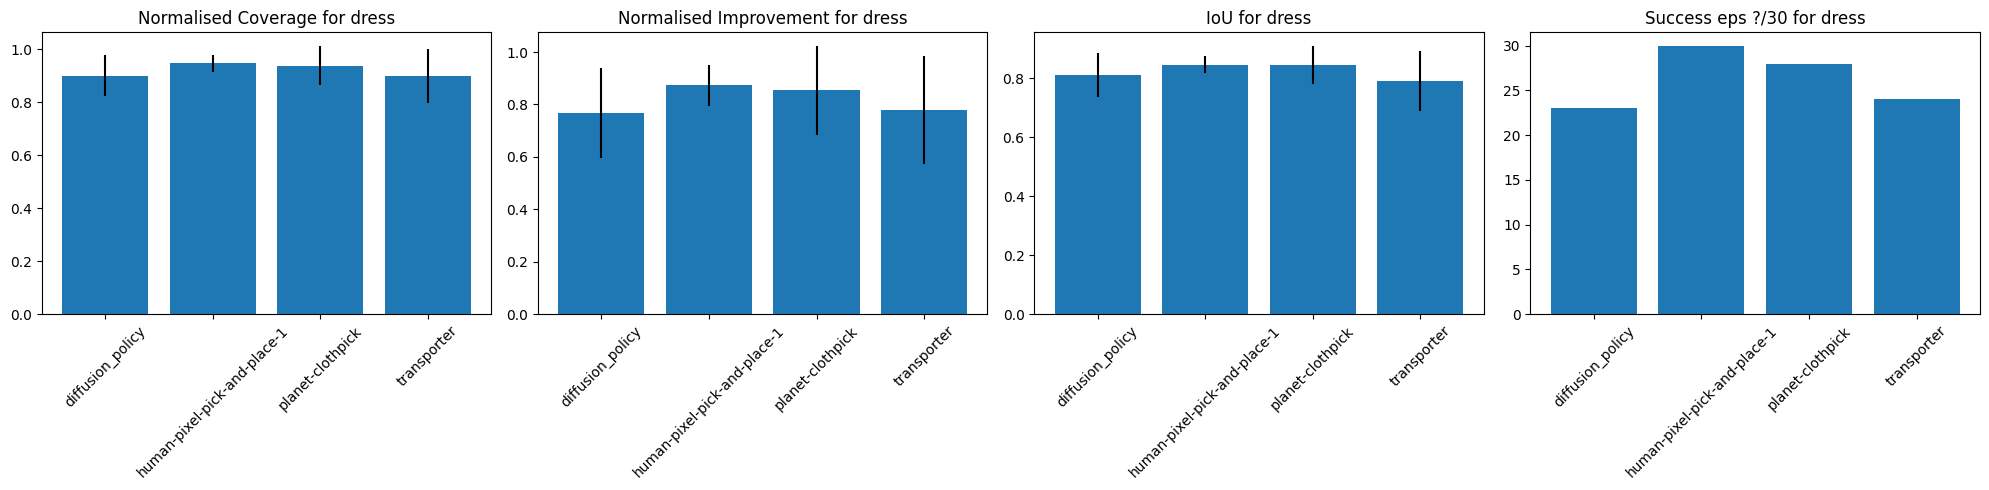

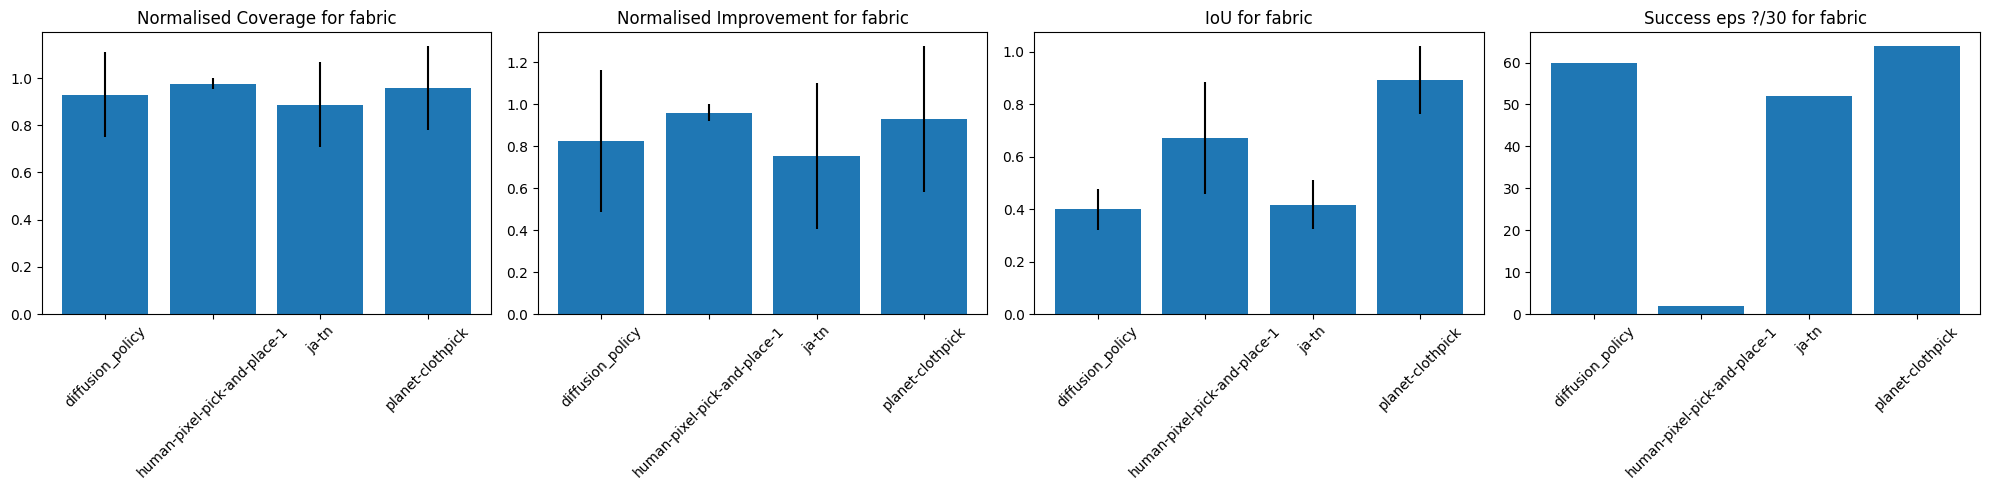

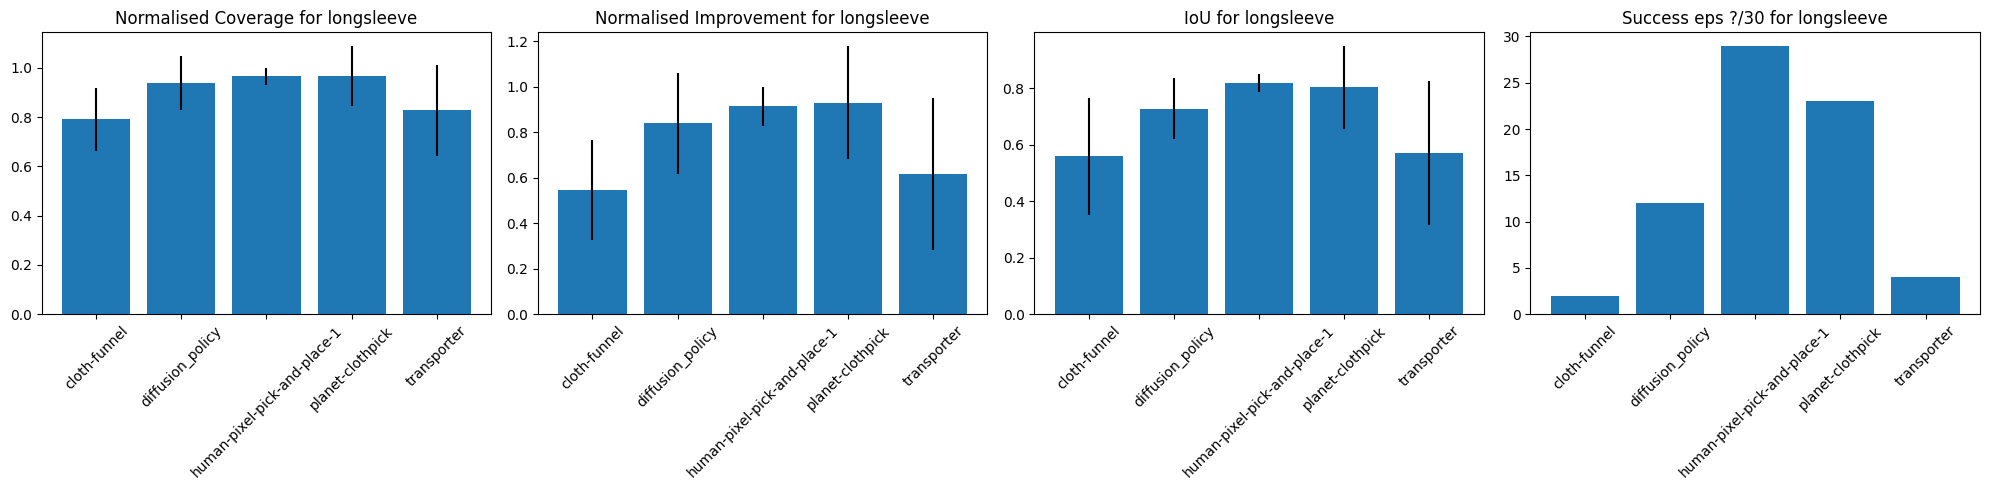

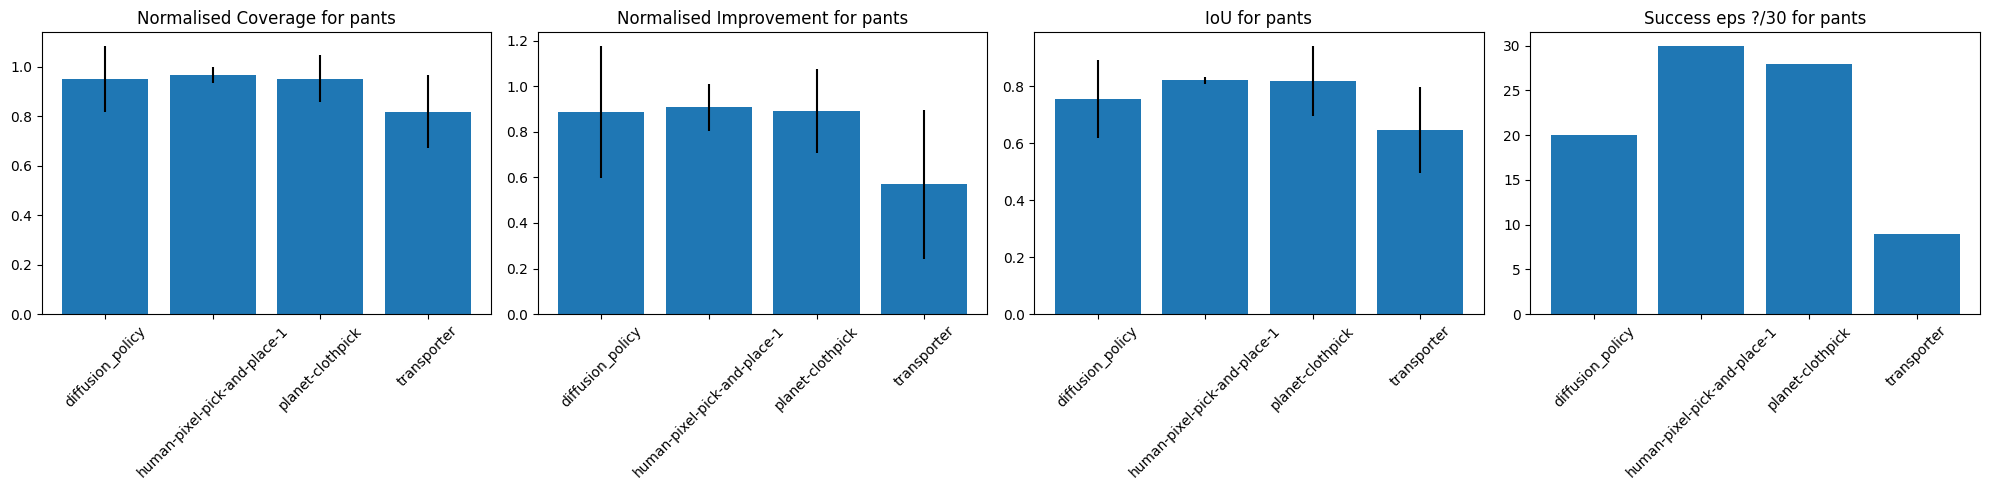

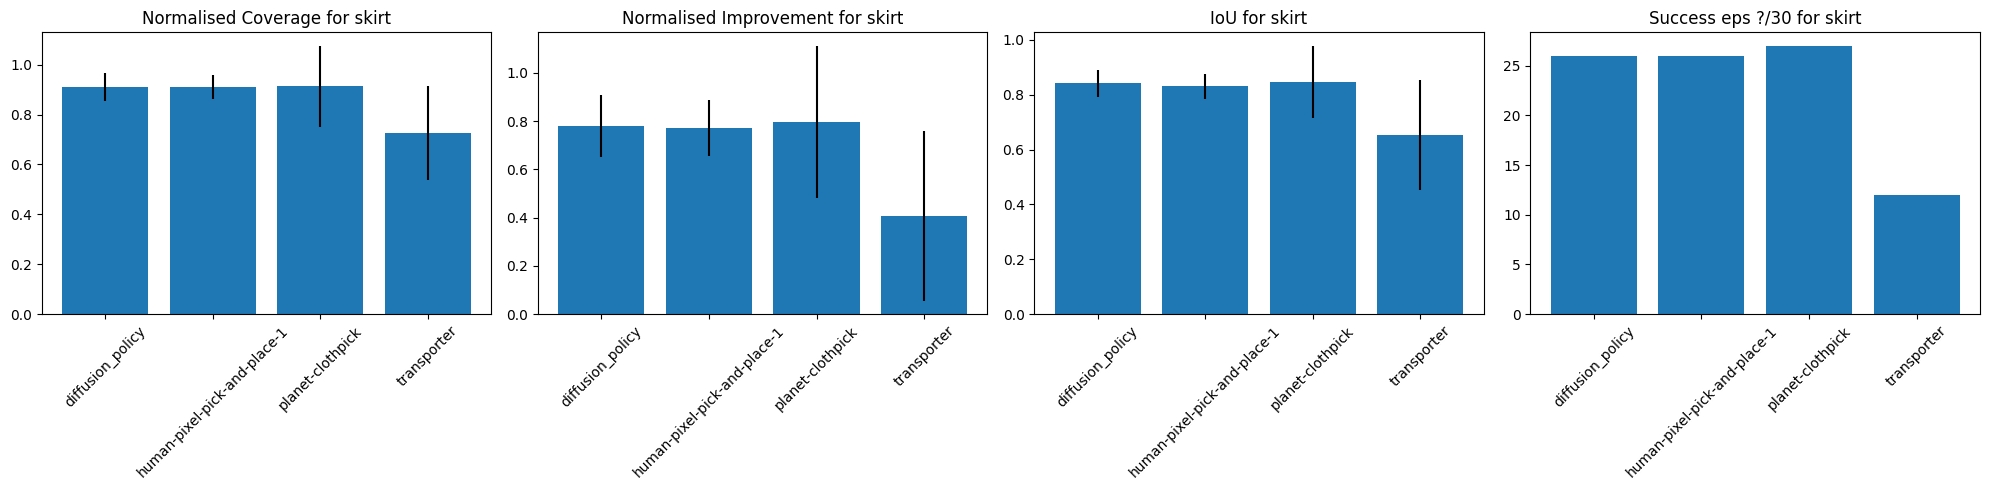

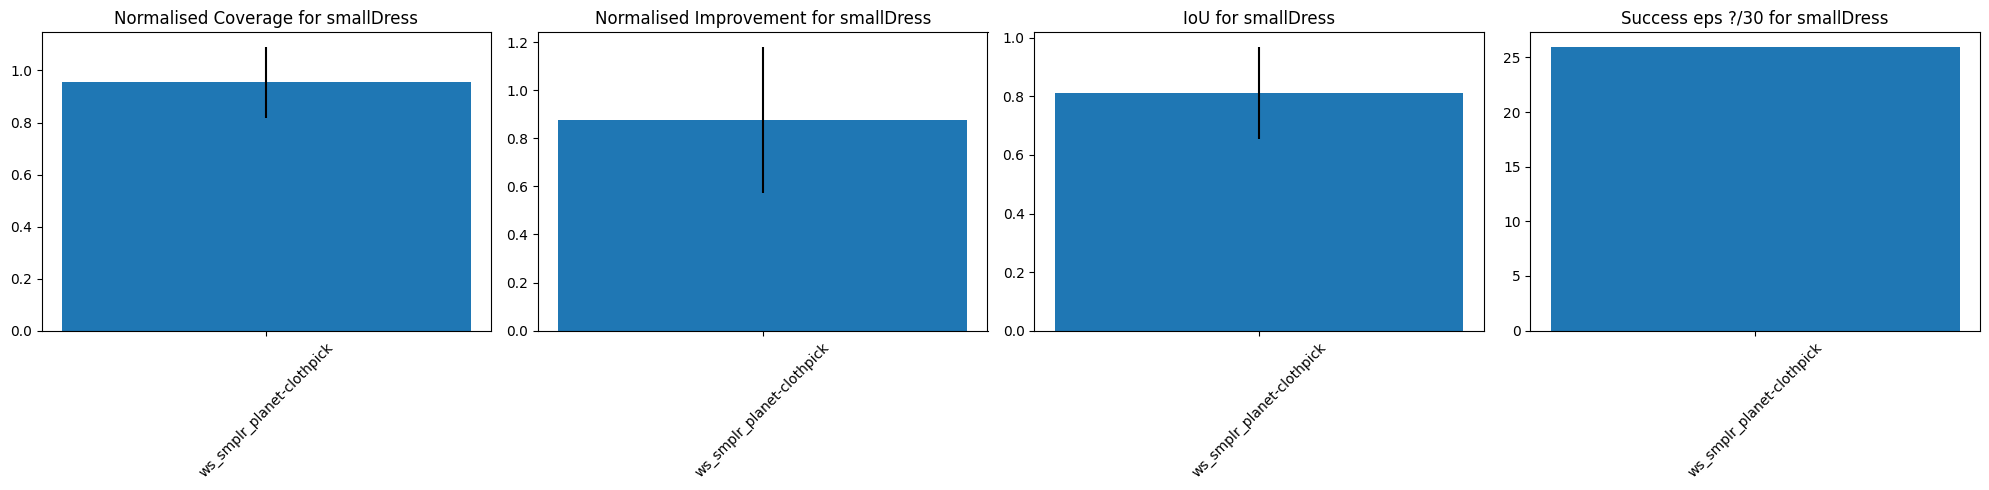

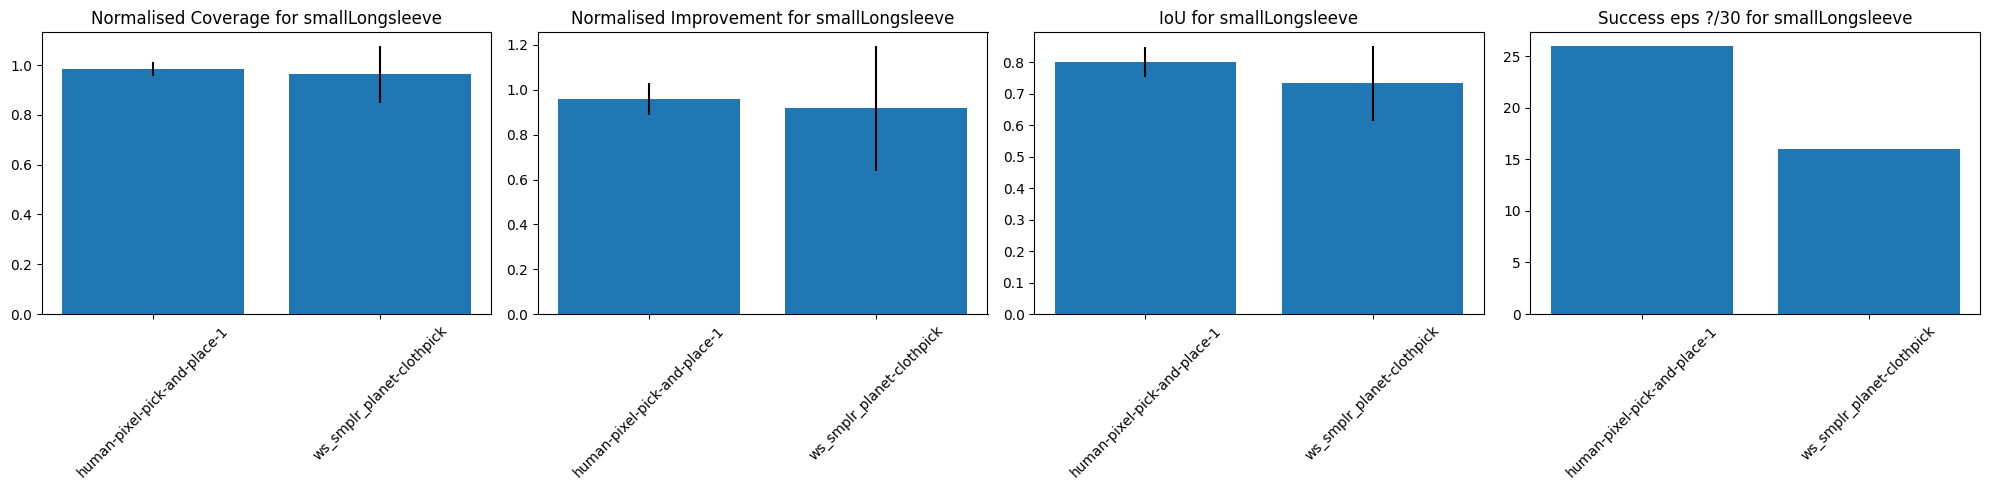

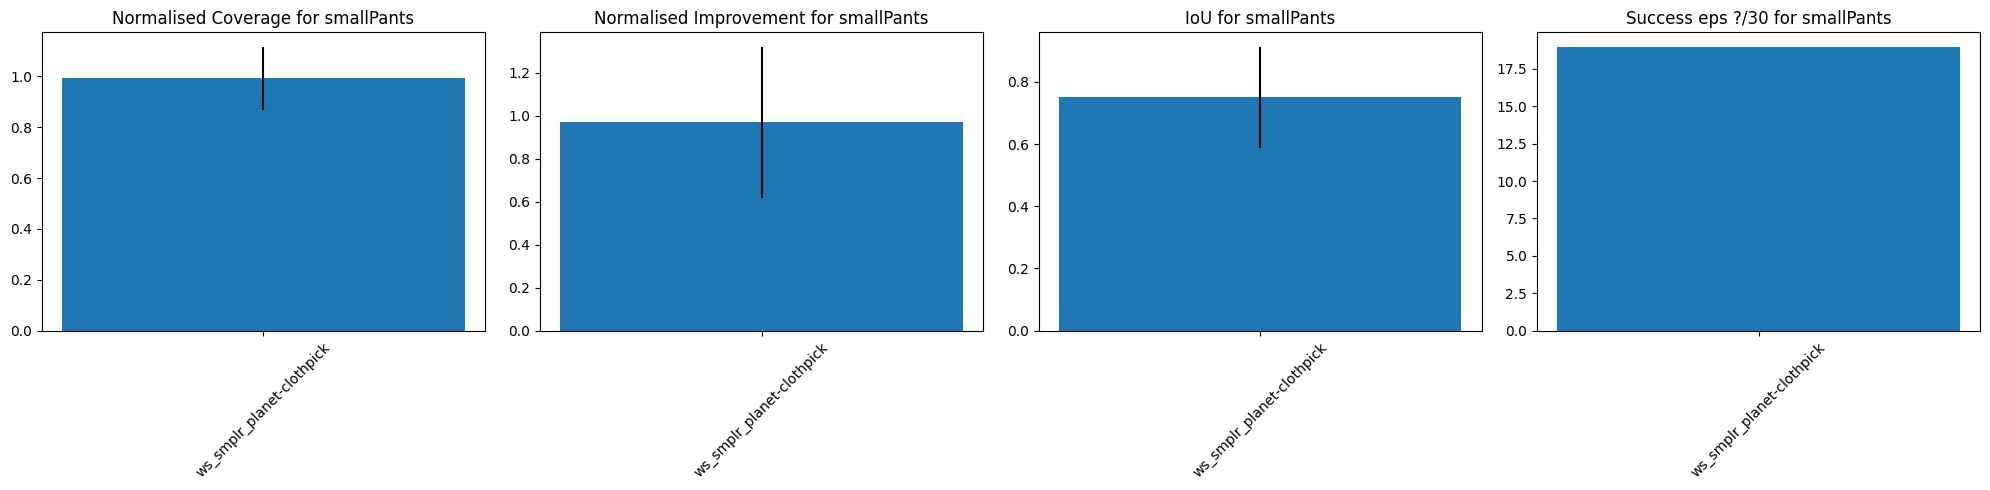

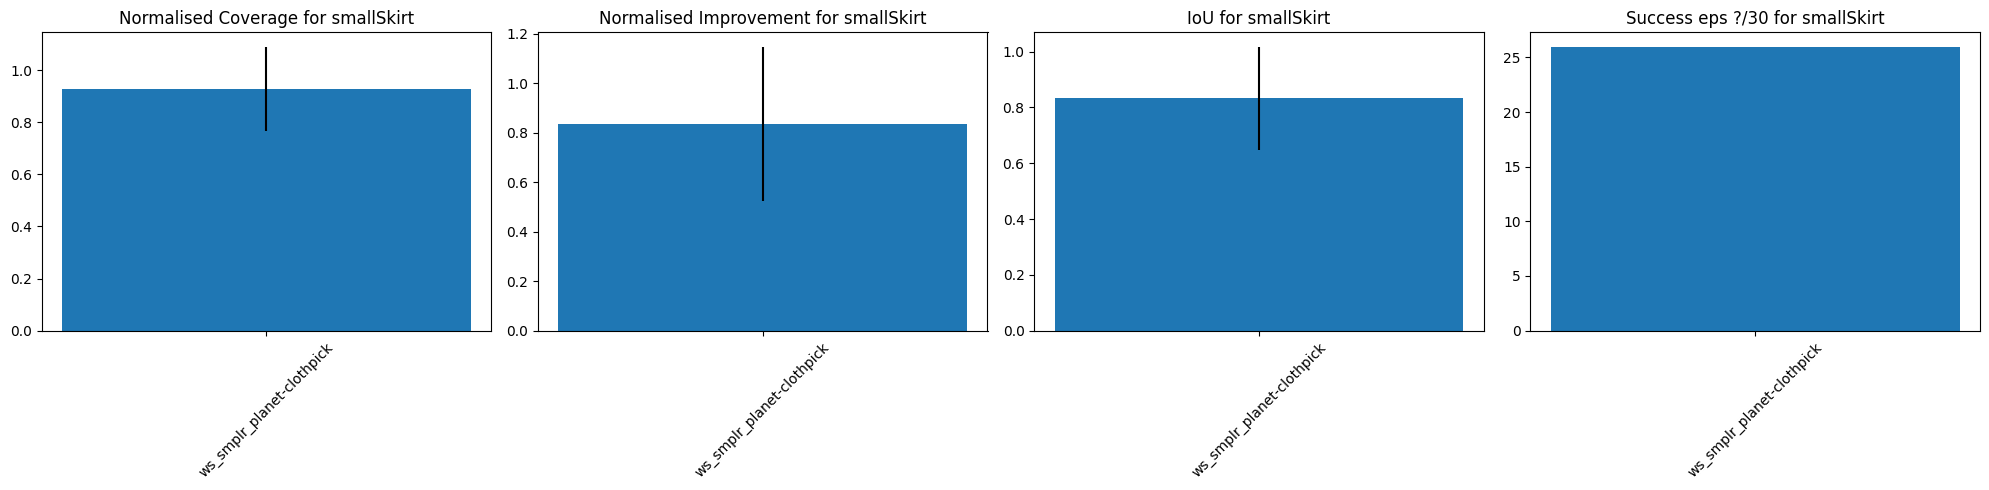

In [5]:
# get the best rows for the largest success_eps	 for each (agent, domain, object, configs).
plt_df = df.groupby(['agent', 'domain', 'object']).max('success_eps').reset_index()
# sort by object
plt_df = plt_df.sort_values(by=['object', 'agent'])
display(plt_df)

## for each object, plot the NI, NC, IoU, and success rate. on each plot y-axis is the mean and error bar is the std
## the x-axis is the agent

for obj in plt_df['object'].unique():
    
    plt.close()
    plt_df_obj = plt_df[plt_df['object'] == obj]
   
    ## put these plots in a single figure in a row
    fig, axs = plt.subplots(1, 4, figsize=(20, 5))

    axs[0].bar(plt_df_obj['agent'], plt_df_obj['nc'], yerr=plt_df_obj['nc std'])
    axs[0].set_title('Normalised Coverage for {}'.format(obj))
    axs[0].tick_params(axis='x', rotation=45)

    axs[1].bar(plt_df_obj['agent'], plt_df_obj['ni'], yerr=plt_df_obj['ni std'])
    axs[1].set_title('Normalised Improvement for {}'.format(obj))
    axs[1].tick_params(axis='x', rotation=45)

    axs[2].bar(plt_df_obj['agent'], plt_df_obj['IoU'], yerr=plt_df_obj['IoU std'])
    axs[2].set_title('IoU for {}'.format(obj))
    axs[2].tick_params(axis='x', rotation=45)

    axs[3].bar(plt_df_obj['agent'], plt_df_obj['success_eps'])
    axs[3].set_title('Success eps ?/30 for {}'.format(obj))
    axs[3].tick_params(axis='x', rotation=45)


    plt.tight_layout()
    #plt.savefig(os.path.join(analysis_pth, 'plots', obj + '.png'))
    plt.show()

    






In [6]:
ur3e_df = df[(df['domain'].str.contains('ur3e')) & (df['config'].str.contains('GC-MD2M-on-mix-200k-sf-goal-rotate-translate-all-garments'))]

## get rigd of the small prefix of the objects
ur3e_df['object'] = ur3e_df['object'].str.replace('small', '').str.lower()

## make domain name as "UR3e Small Garment"
ur3e_df['domain'] = 'UR3e Small Garments'

clothfunnels_df = df[(df['domain'].str.contains('clothfunnels')) \
                    & (df['config'].str.contains('GC-MD2M-on-mix-200k-sf-goal-rotate-translate-all-garments')) \
                    & (df['checkpoint'] == '50000')]

# display(clothfunnels_df)
clothfunnels_df['domain'] = 'Clothfunnels RealAdapt Garments'

data_df = pd.concat([ur3e_df, clothfunnels_df])

# captalise all the objects
data_df['object'] = data_df['object'].str.capitalize()


# create latex table, domains are columns, rows are objects, for each column there are subcolumns for NI, NC, IoU, Success Rate
# for each subcolumn, there are mean and std

def combine_mean_std(row, metric, scale=100):
    mean = row[metric]*scale
    std = row[f"{metric} std"]*scale
    return f"{mean:.1f} $\pm$ {std:.1f}"

# List of metrics to combine
metrics = ['ni', 'nc', 'IoU']
labels = ['NI', 'NC', 'IoU']

# Apply the combination for each metric
for m, l in zip(metrics, labels):
    data_df[f"{l}"] = data_df.apply(lambda row: combine_mean_std(row, m), axis=1)

data_df['SR'] = data_df['success_eps'].apply(lambda x: f"{x}/30")

display(data_df)

#### generat a latext table where rows are 'objects', outer columns are 'domains', 
#### and subcolumns of each outer columns are the values for NI, NC, IoU, and SR.
def generate_latex_table(data_df):
    domains = ['Clothfunnels RealAdapt Garments', 'UR3e Small Garments']
    objects = data_df['object'].unique()

    latex_table = "\\begin{table}[]\n\\begin{tabular}{l|cccc|cccc}\n"
    latex_table += "Object &  \multicolumn{4}{c|}{\\textit{Clothfunnels Real2Sim Garments}} & \multicolumn{4}{c}{\\textit{UR3e Small Garments}}  \\\\\n"
    latex_table += "\\hline\n"
    ## write out NI, NC, IoU, SR for each column
    latex_table += " Garment Type \\textbackslash Metrics & NI & NC & IoU & SR & NI & NC & IoU & SR \\\\"
    latex_table += "\\hline\n"
    for obj in objects:
        latex_table += f"{obj} & "
        for domain in domains:
            print(obj, domain)
            sub_df = data_df[(data_df['object'] == obj) & (data_df['domain'] == domain)]
            for metric in ['NI', 'NC', 'IoU', 'SR']:
                latex_table += f"{sub_df[metric].values[0]} & "
        latex_table = latex_table[:-2] + "\\\\\n"
    latex_table += "\\end{tabular}\n\\end{table}"
    return latex_table

latex_table = generate_latex_table(data_df)
print(latex_table)


/home/ah390/anaconda3/envs/agent-arena-v0/lib/python3.7/site-packages/ipykernel_launcher.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  after removing the cwd from sys.path.
/home/ah390/anaconda3/envs/agent-arena-v0/lib/python3.7/site-packages/ipykernel_launcher.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  import sys
/home/ah390/anaconda3/envs/agent-arena-v0/lib/python3.7/site-packages/ipykernel_launcher.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a Data

,task,agent,config,domain,object,ni,nc,ni std,nc std,IoU,...,HD std,steps,steps std,episodes,success_eps,path,checkpoint,NI,NC,SR
79,flattening,ws_smplr_planet-clothpick,GC-MD2M-on-mix-200k-sf-goal-rotate-translate-a...,UR3e Small Garments,Longsleeve,0.832426,0.932222,0.177230,0.075068,69.7 $\pm$ 11.2,...,0.027840,25.033333,7.373300,30,11,/data/planet-clothpick++/softgym|domain:ur3e-s...,-1,83.2 $\pm$ 17.7,93.2 $\pm$ 7.5,11/30
99,flattening,ws_smplr_planet-clothpick,GC-MD2M-on-mix-200k-sf-goal-rotate-translate-a...,UR3e Small Garments,Pants,0.969652,0.993327,0.072990,0.017823,75.1 $\pm$ 11.4,...,0.021279,18.333333,10.539871,30,19,/data/planet-clothpick++/softgym|domain:ur3e-s...,-1,97.0 $\pm$ 7.3,99.3 $\pm$ 1.8,19/30
115,flattening,ws_smplr_planet-clothpick,GC-MD2M-on-mix-200k-sf-goal-rotate-translate-a...,UR3e Small Garments,Skirt,0.836638,0.928409,0.122937,0.063485,83.2 $\pm$ 4.8,...,0.019491,8.133333,10.372185,30,26,/data/planet-clothpick++/softgym|domain:ur3e-s...,-1,83.7 $\pm$ 12.3,92.8 $\pm$ 6.3,26/30
129,flattening,ws_smplr_planet-clothpick,GC-MD2M-on-mix-200k-sf-goal-rotate-translate-a...,UR3e Small Garments,Dress,0.877753,0.954727,0.106987,0.046482,81.3 $\pm$ 5.8,...,0.024076,12.233333,10.381661,30,26,/data/planet-clothpick++/softgym|domain:ur3e-s...,-1,87.8 $\pm$ 10.7,95.5 $\pm$ 4.6,26/30
29,flattening,planet-clothpick,GC-MD2M-on-mix-200k-sf-goal-rotate-translate-a...,Clothfunnels RealAdapt Garments,Longsleeve,0.838299,0.927103,0.177410,0.085017,74.1 $\pm$ 10.1,...,0.025325,23.966667,9.214059,30,14,/data/planet-clothpick++/softgym|domain:clothf...,50000,83.8 $\pm$ 17.7,92.7 $\pm$ 8.5,14/30
93,flattening,planet-clothpick,GC-MD2M-on-mix-200k-sf-goal-rotate-translate-a...,Clothfunnels RealAdapt Garments,Pants,0.816138,0.922266,0.173824,0.074980,74.0 $\pm$ 12.3,...,0.016320,19.133333,10.803497,30,18,/data/planet-clothpick++/softgym|domain:clothf...,50000,81.6 $\pm$ 17.4,92.2 $\pm$ 7.5,18/30
107,flattening,planet-clothpick,GC-MD2M-on-mix-200k-sf-goal-rotate-translate-a...,Clothfunnels RealAdapt Garments,Skirt,0.797480,0.913350,0.122729,0.062800,84.7 $\pm$ 5.2,...,0.011428,14.266667,8.932836,30,26,/data/planet-clothpick++/softgym|domain:clothf...,50000,79.7 $\pm$ 12.3,91.3 $\pm$ 6.3,26/30
121,flattening,planet-clothpick,GC-MD2M-on-mix-200k-sf-goal-rotate-translate-a...,Clothfunnels RealAdapt Garments,Dress,0.817147,0.922282,0.087780,0.044798,83.3 $\pm$ 3.4,...,0.011733,13.900000,9.089738,30,27,/data/planet-clothpick++/softgym|domain:clothf...,50000,81.7 $\pm$ 8.8,92.2 $\pm$ 4.5,27/30


Longsleeve Clothfunnels RealAdapt Garments
Longsleeve UR3e Small Garments
Pants Clothfunnels RealAdapt Garments
Pants UR3e Small Garments
Skirt Clothfunnels RealAdapt Garments
Skirt UR3e Small Garments
Dress Clothfunnels RealAdapt Garments
Dress UR3e Small Garments
\begin{table}[]
\begin{tabular}{l|cccc|cccc}
Object &  \multicolumn{4}{c|}{\textit{Clothfunnels Real2Sim Garments}} & \multicolumn{4}{c}{\textit{UR3e Small Garments}}  \\
\hline
 Garment Type \textbackslash Metrics & NI & NC & IoU & SR & NI & NC & IoU & SR \\\hline
Longsleeve & 83.8 $\pm$ 17.7 & 92.7 $\pm$ 8.5 & 74.1 $\pm$ 10.1 & 14/30 & 83.2 $\pm$ 17.7 & 93.2 $\pm$ 7.5 & 69.7 $\pm$ 11.2 & 11/30 \\
Pants & 81.6 $\pm$ 17.4 & 92.2 $\pm$ 7.5 & 74.0 $\pm$ 12.3 & 18/30 & 97.0 $\pm$ 7.3 & 99.3 $\pm$ 1.8 & 75.1 $\pm$ 11.4 & 19/30 \\
Skirt & 79.7 $\pm$ 12.3 & 91.3 $\pm$ 6.3 & 84.7 $\pm$ 5.2 & 26/30 & 83.7 $\pm$ 12.3 & 92.8 $\pm$ 6.3 & 83.2 $\pm$ 4.8 & 26/30 \\
Dress & 81.7 $\pm$ 8.8 & 92.2 $\pm$ 4.5 & 83.3 $\pm$ 3.4 & 27/30 & 87.8 $

In [7]:
data_df_ = df[df['object'] == 'longsleeve']
agent_configs = {
    'human-pixel-pick-and-place-1': {'config': 'default', 'checkpoint': '-1', 'label': 'Human'},
    'transporter': {'config': 'JA-TN-depth-50-human', 'checkpoint': '50001', 'label': 'JA-TN'},
    'diffusion_policy': {'config': 'masked-depth-human-50', 'checkpoint': '45999', 'label': 'Diffusion Policy'},
    'planet-clothpick': {'config': 'GC-D2M-on-mix-100k-sf-goal-rotate-translate', 'checkpoint': '50000', 'label': 'PlaNet-ClothPick\n(Task Focused)'},
    'cloth-funnel': {'config': 'place-only', 'checkpoint': -1, 'label': 'ClothFunnels'},
}

new_configs = {
    'planet-clothpick': {'config': 'GC-MD2M-on-mix-200k-sf-goal-rotate-translate-all-garments', \
                         'checkpoint': '50000', 'label': 'PlaNet-ClothPick\n(All Garments)'},
}

## get the row that the agent keys are in the agent_configs, and its config and checkpoint are in its corresponding values
## using lamda function
data_df = data_df_[data_df_.apply(lambda x: x['agent'] in agent_configs.keys() and x['config'] == agent_configs[x['agent']]['config'] and (x['checkpoint'] == agent_configs[x['agent']]['checkpoint'] or agent_configs[x['agent']]['checkpoint'] == -1), axis=1)]

data_df['agent'] = data_df['agent'].apply(lambda x: agent_configs[x]['label'])

new_df = data_df_[data_df_.apply(lambda x: x['agent'] in new_configs.keys() and x['config'] == new_configs[x['agent']]['config'] and (x['checkpoint'] == new_configs[x['agent']]['checkpoint'] or new_configs[x['agent']]['checkpoint'] == -1), axis=1)]

new_df['agent'] = new_df['agent'].apply(lambda x: new_configs[x]['label'])


data_df = pd.concat([data_df, new_df])
# List of metrics to combine
metrics = ['ni', 'nc', 'IoU', 'steps']
labels = ['NI $\\uparrow$', 'NC $\\uparrow$', 'Max IoU $\\uparrow$', 'S2F $\\downarrow$']

# Apply the combination for each metric
for m, l in zip(metrics, labels):
    if m == 'steps':
        data_df[f"{l}"] = data_df.apply(lambda row: combine_mean_std(row, m, scale=1), axis=1)
    else:
        data_df[f"{l}"] = data_df.apply(lambda row: combine_mean_std(row, m), axis=1)

data_df['SR $\\uparrow$'] = data_df['success_eps'].apply(lambda x: f"{x}/30")

display(data_df)
## create a latex table where columns are the agents, and rows are the metrics

def generate_latex_table(data_df):
    agents = ['ClothFunnels', 'JA-TN', 'Diffusion Policy', \
              'PlaNet-ClothPick\n(Task Focused)', 'PlaNet-ClothPick\n(All Garments)', 'Human']
    metrics = ['NI $\\uparrow$', 'NC $\\uparrow$', 'Max IoU $\\uparrow$', 'S2F $\\downarrow$', 'SR $\\uparrow$']

    latex_table = "\\begin{table}[]\n\\begin{tabular}{l|cccc||c}\n"
    for agent in agents:
        latex_table += f" & {agent}"
    latex_table += "\\\\\n"
    latex_table += "\\hline\n"
    for metric in metrics:
        latex_table += f"{metric} & "
        for agent in agents:
           
            metrics_value = data_df[data_df['agent'] == agent][metric].values[0]
            
            latex_table += f"{metrics_value} & "
        latex_table = latex_table[:-2] + "\\\\\n"
    latex_table += "\\end{tabular}\n\\end{table}"
    return latex_table

latex_table = generate_latex_table(data_df)
print(latex_table)



/home/ah390/anaconda3/envs/agent-arena-v0/lib/python3.7/site-packages/ipykernel_launcher.py:19: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
/home/ah390/anaconda3/envs/agent-arena-v0/lib/python3.7/site-packages/ipykernel_launcher.py:23: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy


,task,agent,config,domain,object,ni,nc,ni std,nc std,IoU,...,steps std,episodes,success_eps,path,checkpoint,NI $\uparrow$,NC $\uparrow$,Max IoU $\uparrow$,S2F $\downarrow$,SR $\uparrow$
0,flattening,Human,default,clothfunnels,longsleeve,0.913370,0.964982,0.086964,0.033188,0.818775,...,8.137704,30,29,/data/planet-clothpick++/softgym|domain:clothf...,-1,91.3 $\pm$ 8.7,96.5 $\pm$ 3.3,81.9 $\pm$ 3.2,13.3 $\pm$ 8.1,29/30
2,flattening,JA-TN,JA-TN-depth-50-human,clothfunnels,longsleeve,0.422677,0.704962,0.325279,0.183584,0.571371,...,4.962526,30,4,/data/planet-clothpick++/softgym|domain:clothf...,50001,42.3 $\pm$ 32.5,70.5 $\pm$ 18.4,57.1 $\pm$ 14.2,28.2 $\pm$ 5.0,4/30
5,flattening,ClothFunnels,place-only,clothfunnels,longsleeve,0.546149,0.790867,0.219827,0.118845,0.559076,...,0.718022,30,2,/data/planet-clothpick++/softgym|domain:clothf...,-1,54.6 $\pm$ 22.0,79.1 $\pm$ 11.9,55.9 $\pm$ 15.2,29.9 $\pm$ 0.7,2/30
9,flattening,Diffusion Policy,masked-depth-human-50,clothfunnels,longsleeve,0.838246,0.925313,0.161056,0.073503,0.727183,...,6.287200,30,12,/data/planet-clothpick++/softgym|domain:clothf...,45999,83.8 $\pm$ 16.1,92.5 $\pm$ 7.4,72.7 $\pm$ 9.2,26.1 $\pm$ 6.3,12/30
22,flattening,PlaNet-ClothPick\n(Task Focused),GC-D2M-on-mix-100k-sf-goal-rotate-translate,clothfunnels,longsleeve,0.834054,0.927010,0.152941,0.068930,0.785864,...,9.223701,30,23,/data/planet-clothpick++/softgym|domain:clothf...,50000,83.4 $\pm$ 15.3,92.7 $\pm$ 6.9,78.6 $\pm$ 8.5,18.3 $\pm$ 9.2,23/30
29,flattening,PlaNet-ClothPick\n(All Garments),GC-MD2M-on-mix-200k-sf-goal-rotate-translate-a...,clothfunnels,longsleeve,0.838299,0.927103,0.177410,0.085017,0.741173,...,9.214059,30,14,/data/planet-clothpick++/softgym|domain:clothf...,50000,83.8 $\pm$ 17.7,92.7 $\pm$ 8.5,74.1 $\pm$ 10.1,24.0 $\pm$ 9.2,14/30


\begin{table}[]
\begin{tabular}{l|cccc||c}
 & ClothFunnels & JA-TN & Diffusion Policy & PlaNet-ClothPick
(Task Focused) & PlaNet-ClothPick
(All Garments) & Human\\
\hline
NI $\uparrow$ & 54.6 $\pm$ 22.0 & 42.3 $\pm$ 32.5 & 83.8 $\pm$ 16.1 & 83.4 $\pm$ 15.3 & 83.8 $\pm$ 17.7 & 91.3 $\pm$ 8.7 \\
NC $\uparrow$ & 79.1 $\pm$ 11.9 & 70.5 $\pm$ 18.4 & 92.5 $\pm$ 7.4 & 92.7 $\pm$ 6.9 & 92.7 $\pm$ 8.5 & 96.5 $\pm$ 3.3 \\
Max IoU $\uparrow$ & 55.9 $\pm$ 15.2 & 57.1 $\pm$ 14.2 & 72.7 $\pm$ 9.2 & 78.6 $\pm$ 8.5 & 74.1 $\pm$ 10.1 & 81.9 $\pm$ 3.2 \\
S2F $\downarrow$ & 29.9 $\pm$ 0.7 & 28.2 $\pm$ 5.0 & 26.1 $\pm$ 6.3 & 18.3 $\pm$ 9.2 & 24.0 $\pm$ 9.2 & 13.3 $\pm$ 8.1 \\
SR $\uparrow$ & 2/30 & 4/30 & 12/30 & 23/30 & 14/30 & 29/30 \\
\end{tabular}
\end{table}


/home/ah390/anaconda3/envs/agent-arena-v0/lib/python3.7/site-packages/ipykernel_launcher.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  import sys


,task,agent,config,domain,object,ni,nc,ni std,nc std,IoU,HD,IoU std,HD std,steps,steps std,episodes,success_eps,path,checkpoint
10,flattening,diffusion_policy,masked-depth-human-50,clothfunnels,longsleeve,0.840473,0.923977,0.143023,0.076926,0.683755,0.069530,0.098971,0.025387,26.033333,7.129672,30,9,/data/planet-clothpick++/softgym|domain:clothf...,10000
9,flattening,diffusion_policy,masked-depth-human-50,clothfunnels,longsleeve,0.838246,0.925313,0.161056,0.073503,0.727183,0.059430,0.091832,0.024929,26.066667,6.287200,30,12,/data/planet-clothpick++/softgym|domain:clothf...,46000
8,flattening,diffusion_policy,masked-depth-human-50,clothfunnels,longsleeve,0.787438,0.899349,0.177557,0.086528,0.707047,0.062129,0.109098,0.026845,26.333333,6.326312,30,11,/data/planet-clothpick++/softgym|domain:clothf...,50000
7,flattening,diffusion_policy,masked-depth-human-50,clothfunnels,longsleeve,0.767836,0.893724,0.222228,0.110083,0.706508,0.058092,0.095683,0.018422,26.600000,7.436845,30,8,/data/planet-clothpick++/softgym|domain:clothf...,100000


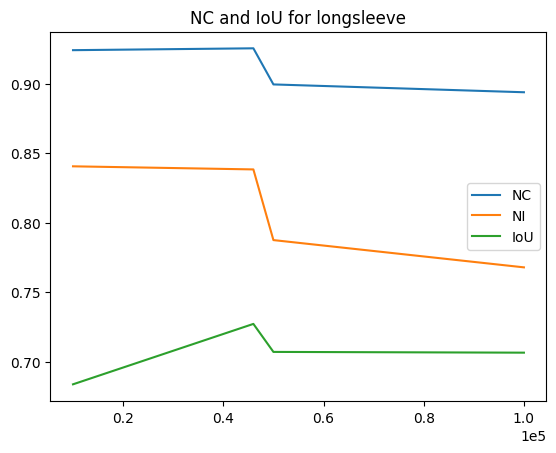

In [8]:
diffusion_df = df[(df['agent'] == 'diffusion_policy') & (df['object'] == 'longsleeve') & (df['config'].str.contains('50'))]
# sort by checkpoint



# +1 to the checkpoint
diffusion_df['checkpoint'] = diffusion_df['checkpoint'].astype(int) + 1
diffusion_df = diffusion_df.sort_values('checkpoint')
display(diffusion_df)

# plot linear plot on IoU and NC for each checkpoint
plt.close()
plt.plot(diffusion_df['checkpoint'], diffusion_df['nc'], label='NC')
plt.plot(diffusion_df['checkpoint'], diffusion_df['ni'], label='NI')
plt.plot(diffusion_df['checkpoint'], diffusion_df['IoU'], label='IoU')
plt.legend()
# make x-asis as scientific notation
plt.ticklabel_format(style='sci', axis='x', scilimits=(0,0))
plt.title('NC and IoU for longsleeve')
plt.show()

,object,domain,agent,config,ni,nc,ni std,nc std,IoU,HD,IoU std,HD std,steps,steps std,episodes,success_eps
0,dress,clothfunnels,planet-clothpick,GC-MD2M-on-mix-200k-ca,0.812791,0.922844,0.078088,0.030080,0.832384,0.035961,0.030983,0.008054,11.866667,8.429050,30,27
1,dress,clothfunnels,planet-clothpick,GC-MD2M-on-mix-200k-ca-all-garments,0.784056,0.911838,0.148183,0.059526,0.821200,0.038400,0.065220,0.015042,12.633333,9.389652,30,25
2,dress,clothfunnels,planet-clothpick,GC-MD2M-on-mix-200k-sf,0.806071,0.920490,0.140211,0.053059,0.824832,0.036335,0.052502,0.010536,12.000000,9.172422,30,26
3,dress,clothfunnels,planet-clothpick,GC-MD2M-on-mix-200k-sf-goal-rotate-translate-a...,0.817147,0.922282,0.087780,0.044798,0.833457,0.036192,0.033614,0.011733,13.900000,9.089738,30,27
4,dress,clothfunnels,planet-clothpick,MD2M-on-mix-200k-ca,0.721421,0.880334,0.170006,0.074726,0.801748,0.040465,0.064451,0.012850,18.566667,11.666714,30,17
5,dress,clothfunnels,planet-clothpick,MD2M-on-mix-200k-sf,0.799063,0.916608,0.104139,0.039607,0.829062,0.037283,0.037187,0.009910,11.500000,8.995369,30,26
6,fabric,mono,planet-clothpick,MD2M-on-mix-200k-sf,0.791645,0.915382,0.281152,0.112070,0.387934,0.033821,0.050884,0.012905,13.907692,8.717309,65,58
7,longsleeve,clothfunnels,planet-clothpick,GC-MD2M-on-mix-200k-ca,0.752367,0.885852,0.184009,0.084683,0.719565,0.069164,0.100085,0.029047,24.566667,8.935634,30,10
8,longsleeve,clothfunnels,planet-clothpick,GC-MD2M-on-mix-200k-ca-all-garments,0.737421,0.889445,0.243553,0.097498,0.705847,0.074507,0.109284,0.033646,24.700000,7.954663,30,12
9,longsleeve,clothfunnels,planet-clothpick,GC-MD2M-on-mix-200k-sf,0.810708,0.912479,0.181529,0.096176,0.735347,0.062695,0.109638,0.028793,21.966667,10.084587,30,16


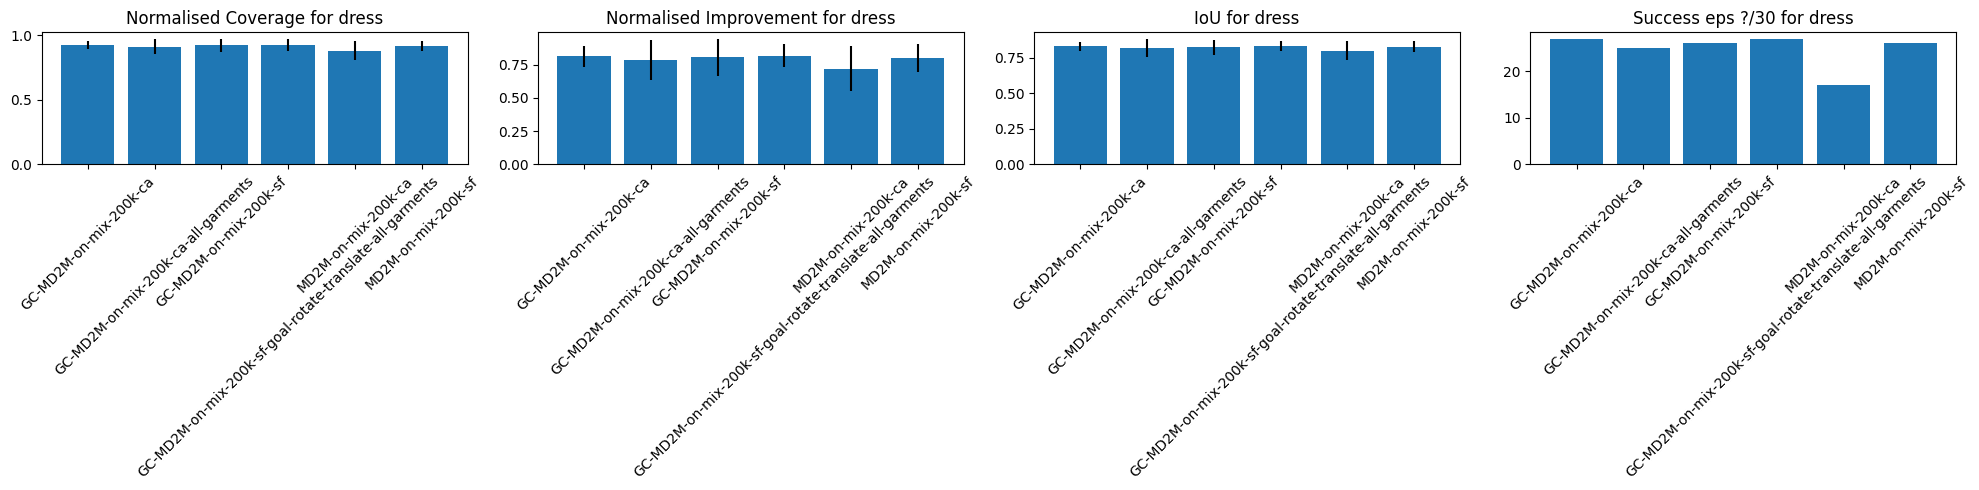

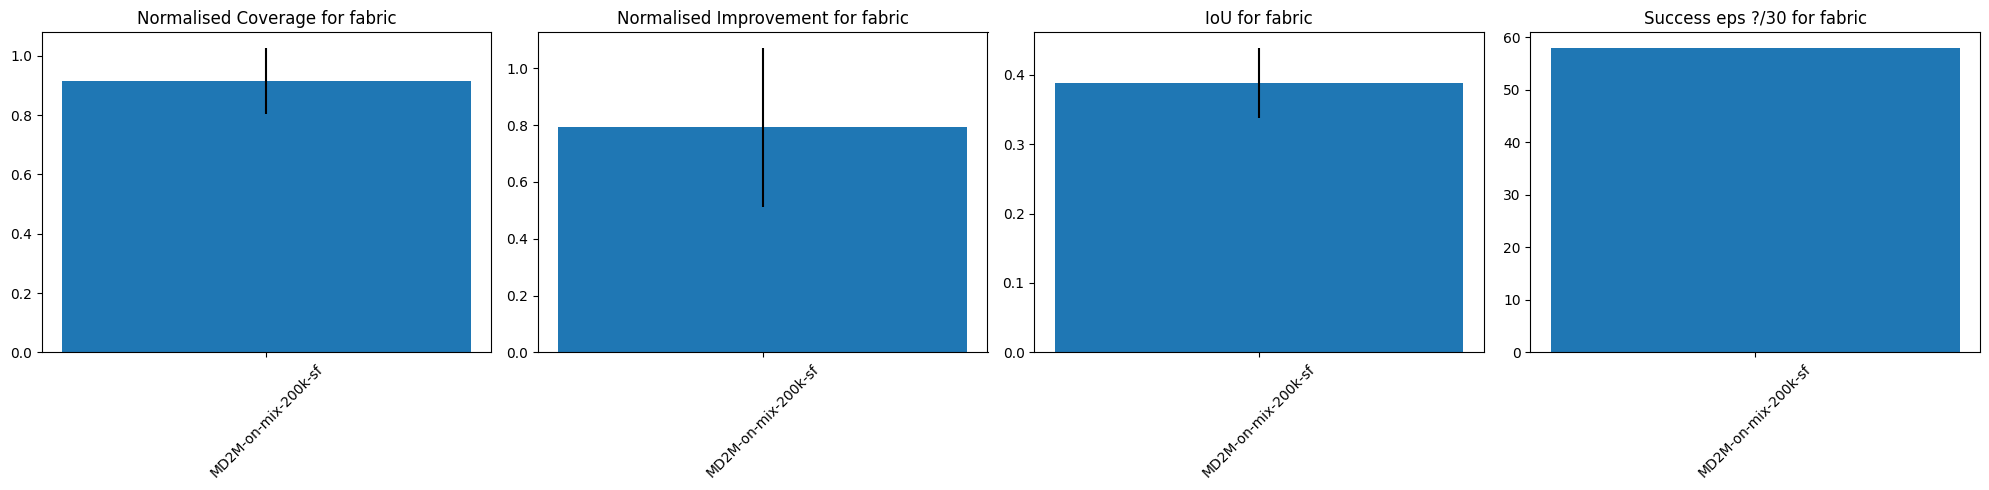

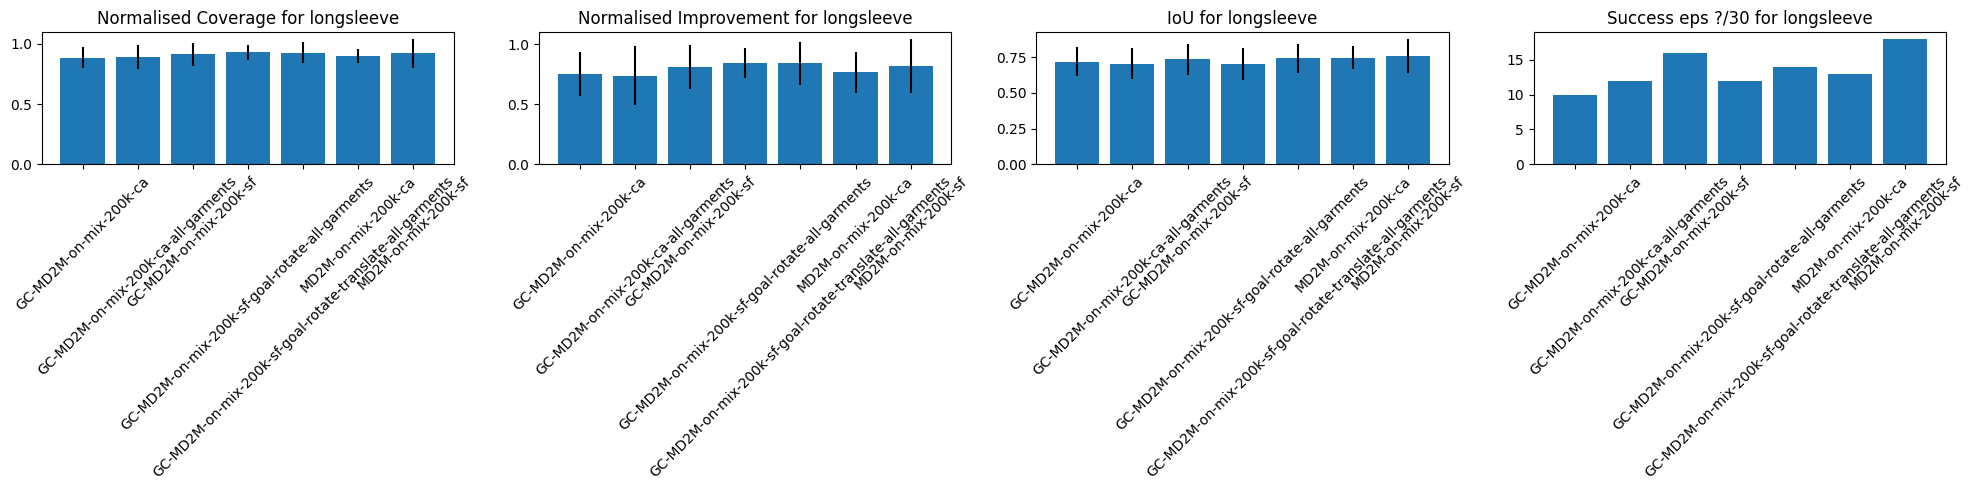

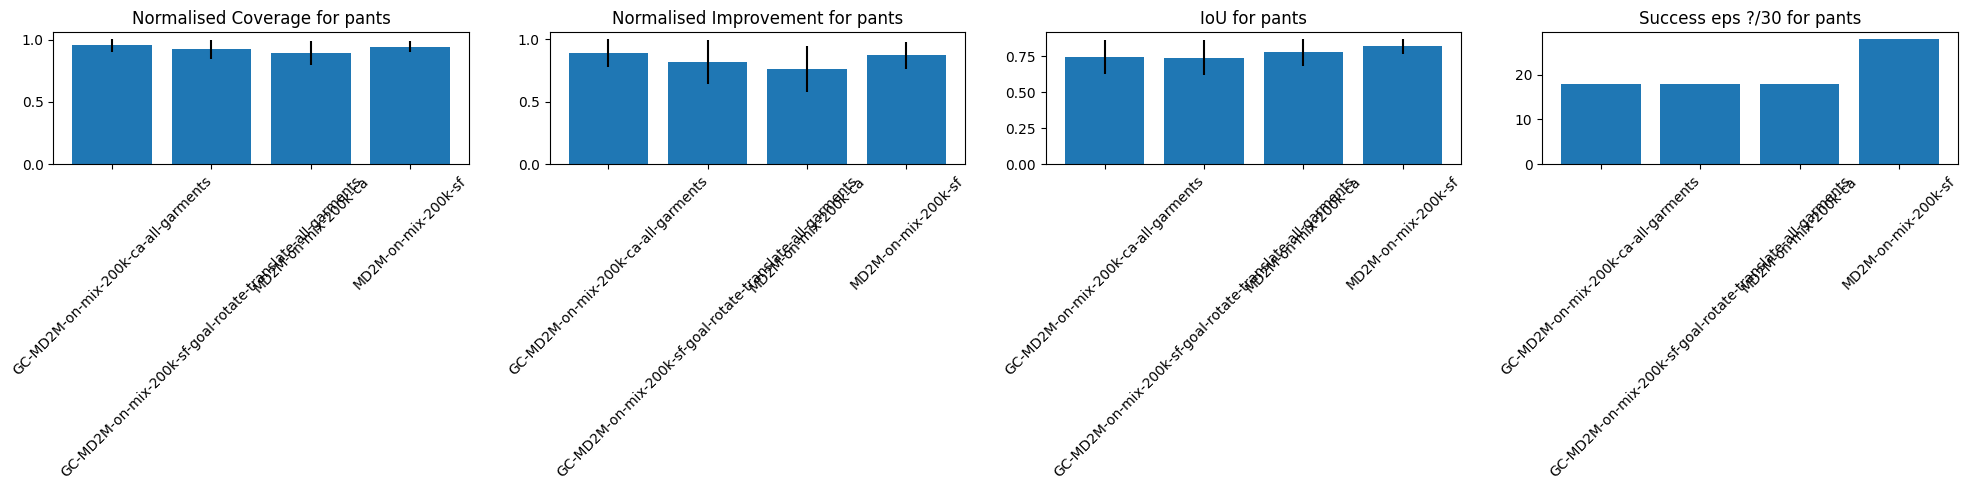

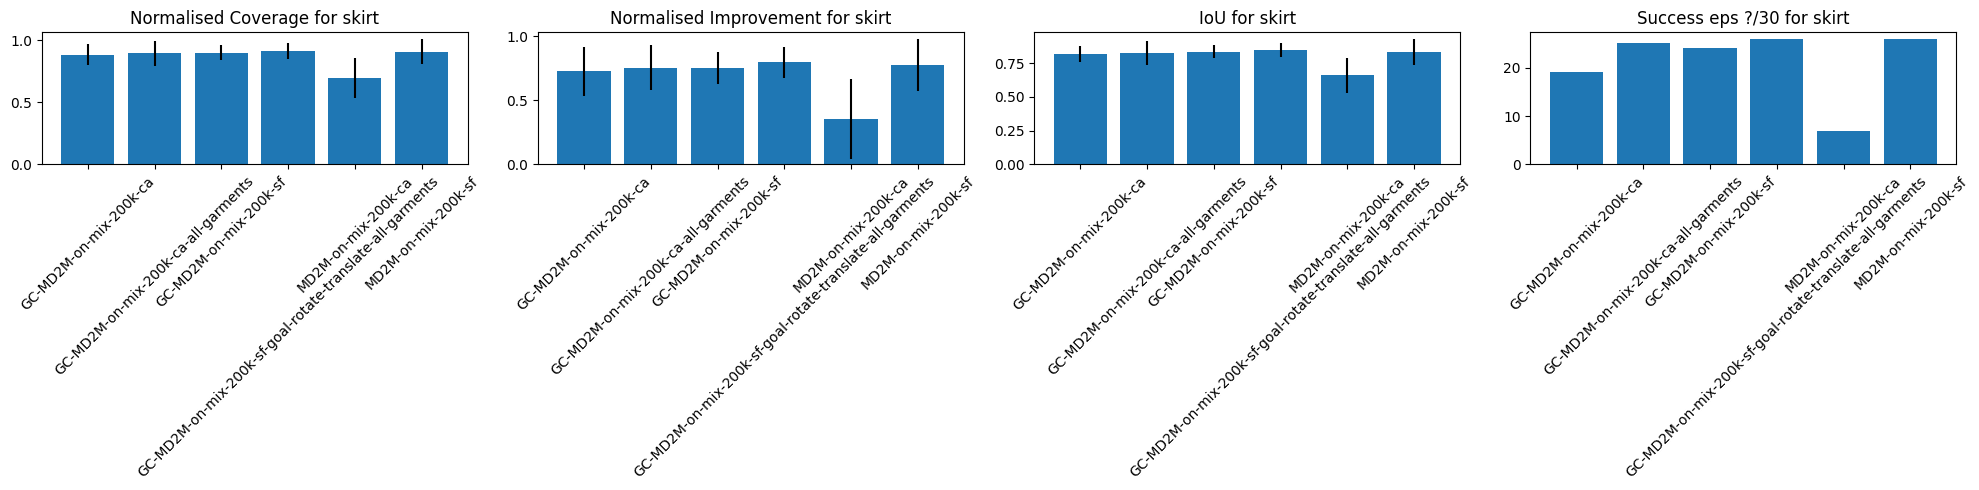

In [9]:
gc_compare_df = df[(df['agent'] == 'planet-clothpick')  & \
    ((df['config'].str.contains('MD2M-on-mix-200k-ca')) | \
     (df['config'].str.contains('GC-MD2M-on-mix-200k-ca')) | \
     (df['config'].str.contains('MD2M-on-mix-200k-sf')) | \
     (df['config'].str.contains('GC-MD2M-on-mix-200k-sf')))]


# sort by object
gc_compare_df = gc_compare_df.sort_values(by=['object'])


## for each object, domain, agent, config get the hightest success_eps
plt_df = gc_compare_df.groupby(['object', 'domain', 'agent', 'config']).max('success_eps').reset_index()
display(plt_df)

## plt NI, NC, IoU, and SR for each object
for obj in plt_df['object'].unique():
    
    plt.close()
    plt_df_obj = plt_df[plt_df['object'] == obj]
   
    ## put these plots in a single figure in a row
    fig, axs = plt.subplots(1, 4, figsize=(20, 5))

    axs[0].bar(plt_df_obj['config'], plt_df_obj['nc'], yerr=plt_df_obj['nc std'])
    axs[0].set_title('Normalised Coverage for {}'.format(obj))
    axs[0].tick_params(axis='x', rotation=45)

    axs[1].bar(plt_df_obj['config'], plt_df_obj['ni'], yerr=plt_df_obj['ni std'])
    axs[1].set_title('Normalised Improvement for {}'.format(obj))
    axs[1].tick_params(axis='x', rotation=45)

    axs[2].bar(plt_df_obj['config'], plt_df_obj['IoU'], yerr=plt_df_obj['IoU std'])
    axs[2].set_title('IoU for {}'.format(obj))
    axs[2].tick_params(axis='x', rotation=45)

    axs[3].bar(plt_df_obj['config'], plt_df_obj['success_eps'])
    axs[3].set_title('Success eps ?/30 for {}'.format(obj))
    axs[3].tick_params(axis='x', rotation=45)


    plt.tight_layout()
    #plt.savefig(os.path.join(analysis_pth, 'plots', obj + '.png'))
    plt.show()


In [10]:
## only print all garment planet-clothpick
planet_df = df[(df['agent'] == 'planet-clothpick') & (df['config'].str.contains('all-garments'))]
display(planet_df)

,task,agent,config,domain,object,ni,nc,ni std,nc std,IoU,HD,IoU std,HD std,steps,steps std,episodes,success_eps,path,checkpoint
27,flattening,planet-clothpick,GC-MD2M-on-mix-200k-sf-goal-rotate-all-garments,clothfunnels,longsleeve,0.841813,0.929922,0.127714,0.060816,0.702490,0.072889,0.113388,0.033180,23.300000,9.798469,30,12,/data/planet-clothpick++/softgym|domain:clothf...,50000
29,flattening,planet-clothpick,GC-MD2M-on-mix-200k-sf-goal-rotate-translate-a...,clothfunnels,longsleeve,0.838299,0.927103,0.177410,0.085017,0.741173,0.058058,0.101310,0.025325,23.966667,9.214059,30,14,/data/planet-clothpick++/softgym|domain:clothf...,50000
41,flattening,planet-clothpick,GC-D2M-on-mix-200k-sf-goal-rotate-translate-al...,clothfunnels,longsleeve,0.750912,0.880090,0.196276,0.103321,0.695280,0.069297,0.124942,0.026017,23.300000,9.452160,30,12,/data/planet-clothpick++/softgym|domain:clothf...,40000
42,flattening,planet-clothpick,GC-D2M-on-mix-200k-sf-goal-rotate-translate-al...,clothfunnels,longsleeve,0.808715,0.914717,0.139726,0.051424,0.691230,0.068287,0.099536,0.024353,24.700000,9.230926,30,8,/data/planet-clothpick++/softgym|domain:clothf...,30000
43,flattening,planet-clothpick,GC-D2M-on-mix-200k-sf-goal-rotate-translate-al...,clothfunnels,longsleeve,0.720783,0.868401,0.229034,0.108395,0.659011,0.082526,0.106496,0.030038,26.700000,7.660070,30,6,/data/planet-clothpick++/softgym|domain:clothf...,50000
56,flattening,planet-clothpick,GC-MD2M-on-mix-200k-ca-all-garments,clothfunnels,longsleeve,0.737421,0.889445,0.243553,0.097498,0.705847,0.074507,0.109284,0.033646,24.700000,7.954663,30,12,/data/planet-clothpick++/softgym|domain:clothf...,50000
93,flattening,planet-clothpick,GC-MD2M-on-mix-200k-sf-goal-rotate-translate-a...,clothfunnels,pants,0.816138,0.922266,0.173824,0.074980,0.740328,0.039762,0.122762,0.016320,19.133333,10.803497,30,18,/data/planet-clothpick++/softgym|domain:clothf...,50000
94,flattening,planet-clothpick,GC-D2M-on-mix-200k-sf-goal-rotate-translate-al...,clothfunnels,pants,0.835806,0.932273,0.095160,0.044115,0.760035,0.038409,0.118653,0.016350,18.966667,10.715980,30,20,/data/planet-clothpick++/softgym|domain:clothf...,40000
95,flattening,planet-clothpick,GC-MD2M-on-mix-200k-ca-all-garments,clothfunnels,pants,0.890808,0.952738,0.112237,0.055132,0.743508,0.040994,0.116902,0.017382,20.033333,9.641865,30,18,/data/planet-clothpick++/softgym|domain:clothf...,50000
107,flattening,planet-clothpick,GC-MD2M-on-mix-200k-sf-goal-rotate-translate-a...,clothfunnels,skirt,0.797480,0.913350,0.122729,0.062800,0.846716,0.036346,0.051525,0.011428,14.266667,8.932836,30,26,/data/planet-clothpick++/softgym|domain:clothf...,50000


In [11]:
fabric_df = df[(df['object'] == 'fabric') & (df['agent'] == 'planet-clothpick')]
display(fabric_df)

,task,agent,config,domain,object,ni,nc,ni std,nc std,IoU,HD,IoU std,HD std,steps,steps std,episodes,success_eps,path,checkpoint
137,flattening,planet-clothpick,GC-D2M-on-mix-100k-sf-goal-rotate-translate-un...,mono,fabric,0.738841,0.883480,0.300853,0.142113,0.860904,0.036180,0.129519,0.015863,16.323077,10.217794,65,51,/data/planet-clothpick++/softgym|domain:mono-s...,50000
138,flattening,planet-clothpick,GC-D2M-on-mix-100k-sf-goal-rotate-translate-go...,mono,fabric,0.867375,0.913791,0.133193,0.096507,0.893805,0.034339,0.095689,0.013259,13.400000,7.770028,15,14,/data/planet-clothpick++/softgym|domain:mono-s...,50000
139,flattening,planet-clothpick,GC-D2M-on-mix-100k-sf-goal-rotate-translate,mono,fabric,0.740229,0.836869,0.225266,0.148413,0.359642,0.043838,0.063133,0.018578,20.256410,9.760512,39,24,/data/planet-clothpick++/softgym|domain:mono-s...,33000
140,flattening,planet-clothpick,GC-D2M-on-mix-100k-sf-goal-rotate-translate,mono,fabric,0.768757,0.897401,0.274600,0.131253,0.873405,0.034327,0.119437,0.015956,14.800000,9.287212,65,56,/data/planet-clothpick++/softgym|domain:mono-s...,50000
141,flattening,planet-clothpick,GC-D2M-on-mix-100k-sf-goal-rotate-translate,mono,fabric,0.476933,0.649716,0.000000,0.000000,0.645859,0.070312,0.000000,0.000000,30.000000,0.000000,1,0,/data/planet-clothpick++/softgym|domain:mono-s...,16000
142,flattening,planet-clothpick,D2M-JATN-vision-100k-v0,mono,fabric,0.849969,0.947637,0.201675,0.031044,0.408876,0.031117,0.029416,0.005803,6.892308,4.472559,65,64,/data/planet-clothpick++/softgym|domain:mono-s...,50000
143,flattening,planet-clothpick,GC-D2M-on-mix-100k-sf-goal-rotate-translate-un...,mono,fabric,0.931899,0.959075,0.050397,0.033248,0.401034,0.027307,0.019215,0.003487,13.666667,9.303524,6,6,/data/planet-clothpick++/softgym|domain:mono-s...,50000
144,flattening,planet-clothpick,GC-D2M-on-mix-100k-sf-goal-rotate-translate-old,mono,fabric,0.599042,0.802570,0.347933,0.177561,0.349761,0.045270,0.078902,0.020140,21.723077,10.294894,65,33,/data/planet-clothpick++/softgym|domain:mono-s...,50000
145,flattening,planet-clothpick,MD2M-on-mix-200k-sf,mono,fabric,0.791645,0.915382,0.281152,0.112070,0.387934,0.033821,0.050884,0.012905,13.907692,8.717309,65,58,/data/planet-clothpick++/softgym|domain:mono-s...,50001


/home/ah390/anaconda3/envs/agent-arena-v0/lib/python3.7/site-packages/ipykernel_launcher.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  
/home/ah390/anaconda3/envs/agent-arena-v0/lib/python3.7/site-packages/ipykernel_launcher.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  after removing the cwd from sys.path.
/home/ah390/anaconda3/envs/agent-arena-v0/lib/python3.7/site-packages/ipykernel_launcher.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try 

,task,agent,config,domain,object,ni,nc,ni std,nc std,IoU,HD,IoU std,HD std,steps,steps std,episodes,success_eps,path,checkpoint
140,flattening,PlaNet-ClothPick++\n(Task Focused),GC-D2M-on-mix-100k-sf-goal-rotate-translate,Mono Square Fabric,fabric,0.768757,0.897401,0.274600,0.131253,0.873405,0.034327,0.119437,0.015956,14.800000,9.287212,65,56,/data/planet-clothpick++/softgym|domain:mono-s...,50000
136,flattening,Diffusion Policy,planet-clothpick++,Mono Square Fabric,fabric,0.826223,0.928101,0.230923,0.082271,0.399926,0.033865,0.042939,0.011915,13.338462,8.675832,65,60,/data/planet-clothpick++/softgym|domain:mono-s...,45999
132,flattening,JA-TN,planet-clothpick++ depth,Mono Square Fabric,fabric,0.754866,0.886132,0.284657,0.144945,0.417733,0.034419,0.076841,0.020599,15.230769,9.830516,65,52,/data/planet-clothpick++/softgym|domain:mono-s...,50001
142,flattening,PlaNet-ClothPick,D2M-JATN-vision-100k-v0,Mono Square Fabric,fabric,0.849969,0.947637,0.201675,0.031044,0.408876,0.031117,0.029416,0.005803,6.892308,4.472559,65,64,/data/planet-clothpick++/softgym|domain:mono-s...,50000


,task,agent,config,domain,object,ni,nc,ni std,nc std,IoU,HD,IoU std,HD std,steps,steps std,episodes,success_eps,path,checkpoint
22,flattening,PlaNet-ClothPick++\n(Task Focused),GC-D2M-on-mix-100k-sf-goal-rotate-translate,ClothFunnels \nRealAdapt Longsleeve,longsleeve,0.834054,0.927010,0.152941,0.068930,0.785864,0.051241,0.084614,0.019889,18.300000,9.223701,30,23,/data/planet-clothpick++/softgym|domain:clothf...,50000
8,flattening,Diffusion Policy,masked-depth-human-50,ClothFunnels \nRealAdapt Longsleeve,longsleeve,0.787438,0.899349,0.177557,0.086528,0.707047,0.062129,0.109098,0.026845,26.333333,6.326312,30,11,/data/planet-clothpick++/softgym|domain:clothf...,49999
2,flattening,JA-TN,JA-TN-depth-50-human,ClothFunnels \nRealAdapt Longsleeve,longsleeve,0.422677,0.704962,0.325279,0.183584,0.571371,0.098871,0.142010,0.036829,28.200000,4.962526,30,4,/data/planet-clothpick++/softgym|domain:clothf...,50001


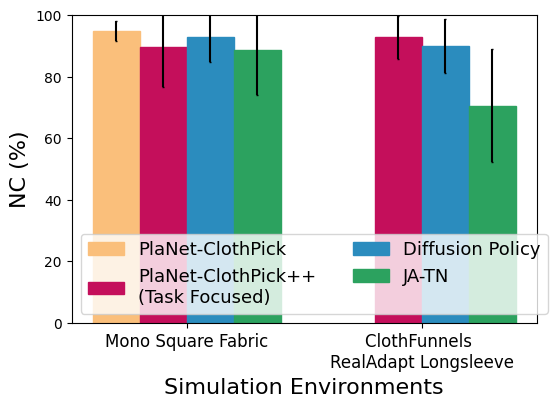

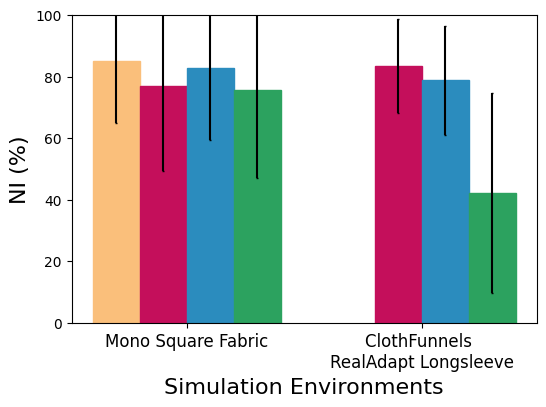

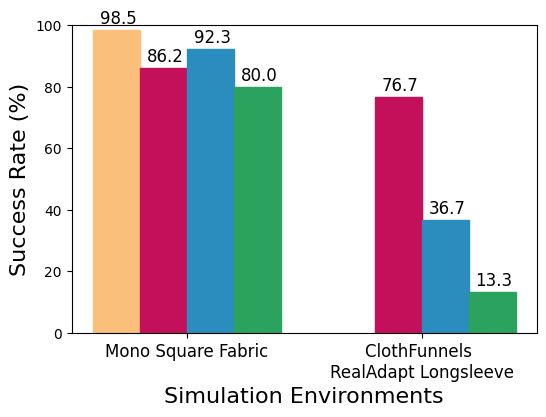

In [12]:
fabric_df = df[df['object'] == 'fabric']
fabric_df['domain'] = 'Mono Square Fabric'
pc_plus_df = fabric_df[(fabric_df['config'] == 'GC-D2M-on-mix-100k-sf-goal-rotate-translate') & (fabric_df['checkpoint'] == '50000')]
pc_plus_df['agent'] = 'PlaNet-ClothPick++\n(Task Focused)'
pc_org_df = fabric_df[(fabric_df['config'] == 'D2M-JATN-vision-100k-v0') & (fabric_df['checkpoint'] == '50000')]
pc_org_df['agent'] = 'PlaNet-ClothPick'
diffusion_df = fabric_df[(fabric_df['config'] == 'planet-clothpick++') & (fabric_df['checkpoint'] == '45999')]
diffusion_df['agent'] = 'Diffusion Policy'
ja_tn_df = fabric_df[(fabric_df['config'] == 'planet-clothpick++ depth') & (fabric_df['checkpoint'] == '50001')]
ja_tn_df['agent'] = 'JA-TN'
fabric_df = pd.concat([pc_plus_df, diffusion_df, ja_tn_df, pc_org_df])
## replace planet-clothpick with PlaNet-ClothPick(Task Focused)
## replace ja-tn with JA-TN
## replace diffusion_policy with Diffusion Policy
display(fabric_df)



longsleeve_df = df[df['object'] == 'longsleeve']
# display(longsleeve_df)
pc_plus_df = longsleeve_df[(longsleeve_df['config'] == 'GC-D2M-on-mix-100k-sf-goal-rotate-translate') & (longsleeve_df['checkpoint'] == '50000')]
diffusion_df = longsleeve_df[(longsleeve_df['config'].str.contains('masked-depth-human-50') & (longsleeve_df['checkpoint'] == '49999'))]
ja_tn_df = longsleeve_df[(longsleeve_df['config'] == 'JA-TN-depth-50-human') & (longsleeve_df['checkpoint'] == '50001')]
longsleeve_df = pd.concat([pc_plus_df, diffusion_df, ja_tn_df])
longsleeve_df['domain'] = 'ClothFunnels \nRealAdapt Longsleeve'
## replace planet-clothpick with PlaNet-ClothPick(Task Focused)
## replace transporter with JA-TN
## replace diffusion_policy with Diffusion Policy
longsleeve_df['agent'] = longsleeve_df['agent'].apply(lambda x: 'PlaNet-ClothPick++\n(Task Focused)' if x == 'planet-clothpick' else x)
longsleeve_df['agent'] = longsleeve_df['agent'].apply(lambda x: 'JA-TN' if x == 'transporter' else x)
longsleeve_df['agent'] = longsleeve_df['agent'].apply(lambda x: 'Diffusion Policy' if x == 'diffusion_policy' else x)
display(longsleeve_df)

## plot metrics for NI, NC, and SR, each plot is a metric, x-axis is the domain, hue are agents, y-axis is the mean and error bar is the std

## combine fabric_df and longsleeve_df
plt_df = pd.concat([fabric_df, longsleeve_df])
plt_df['nc'] = plt_df['nc']*100
plt_df['ni'] = plt_df['ni']*100
plt_df['nc std'] = plt_df['nc std']*100
plt_df['ni std'] = plt_df['ni std']*100
plt_df['success rate'] = plt_df['success_eps']/plt_df['episodes']*100

domain_order = ['Mono Square Fabric', 'ClothFunnels \nRealAdapt Longsleeve']
agent_order = ['PlaNet-ClothPick', 'PlaNet-ClothPick++\n(Task Focused)', 'Diffusion Policy', 'JA-TN']


colors = ['#FABF7B',
          '#C40F5B', '#2b8cbe',
          '#2ca25f', 
          ]
border_colors = ['#FABF7B',
                 '#C40F5B', '#2b8cbe',
                 '#2ca25f', 
                 ]
## create a list of bar filling style, some can be /
fill_styles = [
               '', '',
               '', ''
               ]


plt.figure(figsize=(6, 4))

# Set font sizes
label_fontsize = 16  # Font size for x-label and y-label
tick_fontsize = 12   # Font size for tick labels
legend_fontsize = 13 # Font size for legend

interval = 0.2
offset = -0.3
err_cap = 1

for i, agent in enumerate(agent_order):
    agent_df = plt_df[plt_df['agent'] == agent]
    # Sort the agent_df by domain_order
    agent_df = agent_df.sort_values(by='domain', key=lambda x: x.map({k: i for i, k in enumerate(domain_order)}))
    len_df = len(agent_df)
    plt.bar(np.arange(len_df) + i * interval + offset,
            agent_df['nc'], yerr=agent_df['nc std'], capsize=err_cap, 
            width=interval, label=agent, color=colors[i], edgecolor=border_colors[i],
            hatch=fill_styles[i])
    
plt.xticks(np.arange(len(domain_order)), domain_order, fontsize=tick_fontsize)
plt.ylabel('NC (%)', fontsize=label_fontsize)
plt.ylim(0, 100)
plt.xlabel('Simulation Environments', fontsize=label_fontsize)
plt.legend(ncol=2, loc='lower left', fontsize=legend_fontsize)
# Save figure with tight bounding box
plt.savefig(os.path.join(analysis_pth, 'fabric-longsleeve-nc.png'), bbox_inches='tight')
plt.show()

# Second plot (NI)
plt.figure(figsize=(6, 4))
for i, agent in enumerate(agent_order):
    agent_df = plt_df[plt_df['agent'] == agent]
    agent_df = agent_df.sort_values(by='domain', key=lambda x: x.map({k: i for i, k in enumerate(domain_order)}))
    len_df = len(agent_df)
    plt.bar(np.arange(len_df) + i * interval + offset,
            agent_df['ni'], yerr=agent_df['ni std'], capsize=err_cap, width=interval, 
            label=agent, color=colors[i], edgecolor=border_colors[i], hatch=fill_styles[i])
    
plt.xticks(np.arange(len(domain_order)), domain_order, fontsize=tick_fontsize)
plt.ylabel('NI (%)', fontsize=label_fontsize)
plt.xlabel('Simulation Environments', fontsize=label_fontsize)
plt.ylim(0, 100)
plt.savefig(os.path.join(analysis_pth, 'fabric-longsleeve-ni.png'), bbox_inches='tight')
plt.show()

# Third plot (Success Rate)
plt.figure(figsize=(6, 4))

for i, agent in enumerate(agent_order):
    agent_df = plt_df[plt_df['agent'] == agent]
    agent_df = agent_df.sort_values(by='domain', key=lambda x: x.map({k: i for i, k in enumerate(domain_order)}))
    len_df = len(agent_df)
    plt.bar(np.arange(len_df) + i * interval + offset,
            agent_df['success rate'], capsize=err_cap, width=interval, label=agent, 
            color=colors[i], edgecolor=border_colors[i], hatch=fill_styles[i])
    
    ## put the success rate on top of the bar
    for j, sr in enumerate(agent_df['success rate']):
        plt.text(j + i * interval + offset-0.07, sr + 2, f"{sr:.1f}", fontsize=12, color='black')
    
plt.xticks(np.arange(len(domain_order)), domain_order, fontsize=tick_fontsize)
plt.ylabel('Success Rate (%)', fontsize=label_fontsize)
plt.xlabel('Simulation Environments', fontsize=label_fontsize)
plt.ylim(0, 100)
# Two-column legend/

# Save figure with tight bounding box
plt.savefig(os.path.join(analysis_pth, 'fabric-longsleeve-sr.png'), bbox_inches='tight')
plt.show()


In [13]:
longsleeve_df = df[(df['object'] == 'longsleeve') & (df['agent'] == 'planet-clothpick')]
# sort by nc
longsleeve_df = longsleeve_df.sort_values(by='nc', ascending=False)
# display the full name of the columns
longsleeve_df['success rate'] = longsleeve_df['success_eps']/longsleeve_df['episodes']

display(longsleeve_df)

# go throught each row print config and ni, nc, iou, and success rate
for i, row in longsleeve_df.iterrows():
    if 'D2M' not in row['config']:
        continue
    print(f"{row['config']}: NI: {row['ni']*100:.1f} NC: {row['nc']*100:.1f} IoU: {row['IoU']:.3f} steps: {row['steps']:.3f} SR: {row['success_eps']}/{row['episodes']}")

print()

for i, row in longsleeve_df.iterrows():
    if 'RGB' not in row['config']:
        continue
    print(f"{row['config']}: NI: {row['ni']*100:.1f} NC: {row['nc']*100:.1f} IoU: {row['IoU']:.3f} steps: {row['steps']:.3f}  SR: {row['success_eps']}/{row['episodes']}")

,task,agent,config,domain,object,ni,nc,ni std,nc std,IoU,HD,IoU std,HD std,steps,steps std,episodes,success_eps,path,checkpoint,success rate
63,flattening,planet-clothpick,RGB2M-on-mix-200k-sf-uncertainty,clothfunnels,longsleeve,0.930406,0.967245,0.000000,0.000000,0.802759,0.042072,0.000000,0.000000,8.000000,0.000000,1,1,/data/planet-clothpick++/softgym|domain:clothf...,50000,1.000000
61,flattening,planet-clothpick,MaskedDepth2MaskedDepth-on-mix-200k-sf,clothfunnels,longsleeve,0.928028,0.966366,0.110339,0.058174,0.776010,0.052212,0.080217,0.020600,20.400000,9.898148,30,19,/data/planet-clothpick++/softgym|domain:clothf...,50000,0.633333
54,flattening,planet-clothpick,GC-D2M-on-mix-100k-sf-goal-rotate-translate-un...,clothfunnels,longsleeve,0.885243,0.947740,0.130966,0.066541,0.781409,0.052114,0.092613,0.027625,20.266667,8.740455,30,20,/data/planet-clothpick++/softgym|domain:clothf...,50000,0.666667
17,flattening,planet-clothpick,GC-RGBD2M-on-mix-100k-sf-goal-rotate-translate...,clothfunnels,longsleeve,0.869601,0.947245,0.114180,0.039592,0.802551,0.047187,0.055222,0.015914,17.304348,9.971415,23,18,/data/planet-clothpick++/softgym|domain:clothf...,50000,0.782609
38,flattening,planet-clothpick,MaskedDepth2MaskedDepth-on-mix-200k-sf-nd,clothfunnels,longsleeve,0.876277,0.946193,0.188676,0.086575,0.755980,0.055308,0.108019,0.024828,20.166667,9.543177,30,18,/data/planet-clothpick++/softgym|domain:clothf...,50000,0.600000
13,flattening,planet-clothpick,GC-D2M-on-mix-100k-sf-goal-rotate-translate-un...,clothfunnels,longsleeve,0.879950,0.944613,0.133030,0.061924,0.778995,0.051651,0.110535,0.025604,20.300000,8.779332,30,21,/data/planet-clothpick++/softgym|domain:clothf...,50000,0.700000
37,flattening,planet-clothpick,MaskedDepth2MaskedDepth-on-mix-200k-sf-nd,clothfunnels,longsleeve,0.865276,0.942974,0.185873,0.085835,0.781479,0.051903,0.107142,0.027874,18.333333,9.696506,30,22,/data/planet-clothpick++/softgym|domain:clothf...,30000,0.733333
25,flattening,planet-clothpick,GC-RGB2M-on-mix-100k-sf-goal-rotate-translate-...,clothfunnels,longsleeve,0.858180,0.936631,0.105473,0.054506,0.756337,0.058192,0.128919,0.032056,20.333333,9.877022,30,19,/data/planet-clothpick++/softgym|domain:clothf...,50000,0.633333
62,flattening,planet-clothpick,MaskedDepth2MaskedDepth-on-mix-200k-sf,clothfunnels,longsleeve,0.840665,0.936430,0.214347,0.079549,0.739480,0.059324,0.106091,0.025162,22.500000,9.076527,30,15,/data/planet-clothpick++/softgym|domain:clothf...,28000,0.500000
68,flattening,planet-clothpick,GC-D2M-on-mask-biased-100k-sf-goal-rotate-tran...,clothfunnels,longsleeve,0.850213,0.934765,0.133415,0.062714,0.731354,0.064787,0.115578,0.031955,22.566667,9.243677,30,14,/data/planet-clothpick++/softgym|domain:clothf...,50000,0.466667


GC-D2M-on-mix-100k-sf-goal-rotate-translate-uncertainty: NI: 88.5 NC: 94.8 IoU: 0.781 steps: 20.267 SR: 20/30
GC-RGBD2M-on-mix-100k-sf-goal-rotate-translate-abl: NI: 87.0 NC: 94.7 IoU: 0.803 steps: 17.304 SR: 18/23
GC-D2M-on-mix-100k-sf-goal-rotate-translate-uncertainty-0.2: NI: 88.0 NC: 94.5 IoU: 0.779 steps: 20.300 SR: 21/30
GC-D2M-on-mask-biased-100k-sf-goal-rotate-translate-abl: NI: 85.0 NC: 93.5 IoU: 0.731 steps: 22.567 SR: 14/30
GC-MD2M-on-mix-200k-sf-goal-rotate-all-garments: NI: 84.2 NC: 93.0 IoU: 0.702 steps: 23.300 SR: 12/30
GC-MD2M-on-mix-200k-sf-goal-rotate-translate-all-garments: NI: 83.8 NC: 92.7 IoU: 0.741 steps: 23.967 SR: 14/30
GC-D2M-on-mix-100k-sf-goal-rotate-translate: NI: 83.4 NC: 92.7 IoU: 0.786 steps: 18.300 SR: 23/30
GC-D2M-on-mix-100k-sf-goal-rotate-translate-abl: NI: 82.8 NC: 92.6 IoU: 0.771 steps: 20.533 SR: 19/30
GC-D2M-on-mix-100k-sf-abl: NI: 83.9 NC: 92.6 IoU: 0.744 steps: 21.933 SR: 18/30
MD2M-on-mix-200k-sf: NI: 81.7 NC: 92.2 IoU: 0.761 steps: 20.767 SR:

In [14]:
longsleeve_df = df[(df['object'] == 'smallLongsleeve')]
# sort by nc
longsleeve_df = longsleeve_df.sort_values(by='nc', ascending=False)
display(longsleeve_df)

## keep the with 'prioritise-middle' in the config
longsleeve_df = longsleeve_df[longsleeve_df['config'].str.contains('prioritise-middle')]
display(longsleeve_df)

,task,agent,config,domain,object,ni,nc,ni std,nc std,IoU,HD,IoU std,HD std,steps,steps std,episodes,success_eps,path,checkpoint
73,flattening,human-pixel-pick-and-place-1,default,ur3e,smallLongsleeve,0.958735,0.984708,0.070746,0.029330,0.800610,0.096123,0.046339,0.020574,17.000000,9.051703,30,26,/data/planet-clothpick++/softgym|domain:ur3e-s...,-1
77,flattening,ws_smplr_planet-clothpick,GC-MD2M-on-mix-200k-sf+cloth-mask-centre-multiple,ur3e,smallLongsleeve,0.917627,0.963632,0.120921,0.056638,0.722583,0.099549,0.119674,0.022441,23.166667,8.978060,30,16,/data/planet-clothpick++/softgym|domain:ur3e-s...,-1
82,flattening,ws_smplr_planet-clothpick,RGB2M-on-mix-200k-sf-uncertainty+cloth-mask-ce...,ur3e,smallLongsleeve,0.860930,0.944491,0.170920,0.068122,0.704230,0.094906,0.089696,0.022362,24.533333,8.991601,30,10,/data/planet-clothpick++/softgym|domain:ur3e-s...,-1
85,flattening,ws_smplr_planet-clothpick,RGB2M-on-mix-200k-sf-uncertainty+cloth-mask-ce...,ur3e,smallLongsleeve,0.864014,0.941749,0.158728,0.069959,0.703836,0.091524,0.104567,0.024151,22.700000,10.331667,30,11,/data/planet-clothpick++/softgym|domain:ur3e-s...,old
74,flattening,ws_smplr_planet-clothpick,RGB2M-on-mix-200k-sf+cloth-mask-centre-multipl...,ur3e,smallLongsleeve,0.856488,0.938742,0.178747,0.078329,0.732271,0.100207,0.099540,0.025373,22.766667,9.813879,30,13,/data/planet-clothpick++/softgym|domain:ur3e-s...,old
79,flattening,ws_smplr_planet-clothpick,GC-MD2M-on-mix-200k-sf-goal-rotate-translate-a...,ur3e,smallLongsleeve,0.832426,0.932222,0.177230,0.075068,0.697448,0.100329,0.111577,0.027840,25.033333,7.373300,30,11,/data/planet-clothpick++/softgym|domain:ur3e-s...,-1
84,flattening,ws_smplr_planet-clothpick,RGB2M-on-mix-200k-sf-uncertainty+cloth-mask-ce...,ur3e,smallLongsleeve,0.819444,0.927377,0.164691,0.069335,0.710644,0.091690,0.097592,0.024427,23.400000,9.031796,30,11,/data/planet-clothpick++/softgym|domain:ur3e-s...,-1
75,flattening,ws_smplr_planet-clothpick,RGB2M-on-mix-200k-sf+cloth-mask-centre-multipl...,ur3e,smallLongsleeve,0.816403,0.925239,0.201789,0.086062,0.723891,0.091376,0.090629,0.027436,22.266667,10.654994,30,12,/data/planet-clothpick++/softgym|domain:ur3e-s...,-1
83,flattening,ws_smplr_planet-clothpick,GC-D2M-on-mix-100k-sf-goal-rotate-translate+cl...,ur3e,smallLongsleeve,0.712527,0.882795,0.278722,0.114080,0.675769,0.087915,0.104106,0.024725,25.166667,8.614265,30,9,/data/planet-clothpick++/softgym|domain:ur3e-s...,-1
80,flattening,ws_smplr_planet-clothpick,GC-RGB2M-on-mix-100k-sf-goal-rotate-translate-...,ur3e,smallLongsleeve,0.745206,0.866710,0.125013,0.068115,0.711451,0.085000,0.095970,0.018530,25.400000,5.713143,5,2,/data/planet-clothpick++/softgym|domain:ur3e-s...,-1


,task,agent,config,domain,object,ni,nc,ni std,nc std,IoU,HD,IoU std,HD std,steps,steps std,episodes,success_eps,path,checkpoint
85,flattening,ws_smplr_planet-clothpick,RGB2M-on-mix-200k-sf-uncertainty+cloth-mask-ce...,ur3e,smallLongsleeve,0.864014,0.941749,0.158728,0.069959,0.703836,0.091524,0.104567,0.024151,22.700000,10.331667,30,11,/data/planet-clothpick++/softgym|domain:ur3e-s...,old
74,flattening,ws_smplr_planet-clothpick,RGB2M-on-mix-200k-sf+cloth-mask-centre-multipl...,ur3e,smallLongsleeve,0.856488,0.938742,0.178747,0.078329,0.732271,0.100207,0.099540,0.025373,22.766667,9.813879,30,13,/data/planet-clothpick++/softgym|domain:ur3e-s...,old
75,flattening,ws_smplr_planet-clothpick,RGB2M-on-mix-200k-sf+cloth-mask-centre-multipl...,ur3e,smallLongsleeve,0.816403,0.925239,0.201789,0.086062,0.723891,0.091376,0.090629,0.027436,22.266667,10.654994,30,12,/data/planet-clothpick++/softgym|domain:ur3e-s...,-1
83,flattening,ws_smplr_planet-clothpick,GC-D2M-on-mix-100k-sf-goal-rotate-translate+cl...,ur3e,smallLongsleeve,0.712527,0.882795,0.278722,0.114080,0.675769,0.087915,0.104106,0.024725,25.166667,8.614265,30,9,/data/planet-clothpick++/softgym|domain:ur3e-s...,-1
80,flattening,ws_smplr_planet-clothpick,GC-RGB2M-on-mix-100k-sf-goal-rotate-translate-...,ur3e,smallLongsleeve,0.745206,0.866710,0.125013,0.068115,0.711451,0.085000,0.095970,0.018530,25.400000,5.713143,5,2,/data/planet-clothpick++/softgym|domain:ur3e-s...,-1
81,flattening,ws_smplr_planet-clothpick,GC-D2M-on-mix-100k-sf-goal-rotate-translate-un...,ur3e,smallLongsleeve,0.623294,0.855054,0.264995,0.102386,0.681360,0.084107,0.102227,0.025892,24.933333,9.139414,30,8,/data/planet-clothpick++/softgym|domain:ur3e-s...,-1


In [15]:
mono_df = df[(df['object'] == 'fabric') & (df['agent'] == 'planet-clothpick')]
display(mono_df)

,task,agent,config,domain,object,ni,nc,ni std,nc std,IoU,HD,IoU std,HD std,steps,steps std,episodes,success_eps,path,checkpoint
137,flattening,planet-clothpick,GC-D2M-on-mix-100k-sf-goal-rotate-translate-un...,mono,fabric,0.738841,0.883480,0.300853,0.142113,0.860904,0.036180,0.129519,0.015863,16.323077,10.217794,65,51,/data/planet-clothpick++/softgym|domain:mono-s...,50000
138,flattening,planet-clothpick,GC-D2M-on-mix-100k-sf-goal-rotate-translate-go...,mono,fabric,0.867375,0.913791,0.133193,0.096507,0.893805,0.034339,0.095689,0.013259,13.400000,7.770028,15,14,/data/planet-clothpick++/softgym|domain:mono-s...,50000
139,flattening,planet-clothpick,GC-D2M-on-mix-100k-sf-goal-rotate-translate,mono,fabric,0.740229,0.836869,0.225266,0.148413,0.359642,0.043838,0.063133,0.018578,20.256410,9.760512,39,24,/data/planet-clothpick++/softgym|domain:mono-s...,33000
140,flattening,planet-clothpick,GC-D2M-on-mix-100k-sf-goal-rotate-translate,mono,fabric,0.768757,0.897401,0.274600,0.131253,0.873405,0.034327,0.119437,0.015956,14.800000,9.287212,65,56,/data/planet-clothpick++/softgym|domain:mono-s...,50000
141,flattening,planet-clothpick,GC-D2M-on-mix-100k-sf-goal-rotate-translate,mono,fabric,0.476933,0.649716,0.000000,0.000000,0.645859,0.070312,0.000000,0.000000,30.000000,0.000000,1,0,/data/planet-clothpick++/softgym|domain:mono-s...,16000
142,flattening,planet-clothpick,D2M-JATN-vision-100k-v0,mono,fabric,0.849969,0.947637,0.201675,0.031044,0.408876,0.031117,0.029416,0.005803,6.892308,4.472559,65,64,/data/planet-clothpick++/softgym|domain:mono-s...,50000
143,flattening,planet-clothpick,GC-D2M-on-mix-100k-sf-goal-rotate-translate-un...,mono,fabric,0.931899,0.959075,0.050397,0.033248,0.401034,0.027307,0.019215,0.003487,13.666667,9.303524,6,6,/data/planet-clothpick++/softgym|domain:mono-s...,50000
144,flattening,planet-clothpick,GC-D2M-on-mix-100k-sf-goal-rotate-translate-old,mono,fabric,0.599042,0.802570,0.347933,0.177561,0.349761,0.045270,0.078902,0.020140,21.723077,10.294894,65,33,/data/planet-clothpick++/softgym|domain:mono-s...,50000
145,flattening,planet-clothpick,MD2M-on-mix-200k-sf,mono,fabric,0.791645,0.915382,0.281152,0.112070,0.387934,0.033821,0.050884,0.012905,13.907692,8.717309,65,58,/data/planet-clothpick++/softgym|domain:mono-s...,50001


/home/ah390/anaconda3/envs/agent-arena-v0/lib/python3.7/site-packages/ipykernel_launcher.py:19: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
/home/ah390/anaconda3/envs/agent-arena-v0/lib/python3.7/site-packages/ipykernel_launcher.py:23: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
/home/ah390/anaconda3/envs/agent-arena-v0/lib/python3.7/site-packages/ipykernel_launcher.py:24: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = va

,task,agent,config,domain,object,ni,nc,ni std,nc std,IoU,HD,IoU std,HD std,steps,steps std,episodes,success_eps,path,checkpoint,f1
15,flattening,planet-clothpick,Default,clothfunnels,longsleeve,0.828224,0.926249,0.135384,0.058331,0.771228,0.054554,0.085327,0.022875,20.533333,9.735616,30,19,/data/planet-clothpick++/softgym|domain:clothf...,50000,84.166019
17,flattening,planet-clothpick,RGB-D Input,clothfunnels,longsleeve,0.869601,0.947245,0.114180,0.039592,0.802551,0.047187,0.055222,0.015914,17.304348,9.971415,23,18,/data/planet-clothpick++/softgym|domain:clothf...,50000,86.891557
23,flattening,planet-clothpick,No Translation Augmentation,clothfunnels,longsleeve,0.809596,0.915067,0.164474,0.079792,0.741634,0.066299,0.110794,0.031478,22.200000,8.364209,30,16,/data/planet-clothpick++/softgym|domain:clothf...,50000,81.927247
28,flattening,planet-clothpick,No Goal Input,clothfunnels,longsleeve,0.806322,0.917604,0.181532,0.076298,0.744012,0.056450,0.120491,0.031886,21.766667,9.002531,30,16,/data/planet-clothpick++/softgym|domain:clothf...,50000,82.174013
36,flattening,planet-clothpick,100k Diffusion \nPolicy Only Data,clothfunnels,longsleeve,0.024291,0.409832,0.061595,0.060912,0.400251,0.158524,0.045751,0.022426,30.000000,0.000000,30,0,/data/planet-clothpick++/softgym|domain:clothf...,50000,40.498519
51,flattening,planet-clothpick,ClothFunnels Reward,clothfunnels,longsleeve,0.006392,0.393940,0.019072,0.052105,0.394432,0.150398,0.046591,0.023930,30.000000,0.000000,30,0,/data/planet-clothpick++/softgym|domain:clothf...,50000,39.418620
52,flattening,planet-clothpick,No Rotation Augmentation,clothfunnels,longsleeve,0.820958,0.919021,0.141818,0.069814,0.751214,0.055466,0.105647,0.024884,21.333333,9.332143,30,17,/data/planet-clothpick++/softgym|domain:clothf...,50000,82.668817
53,flattening,planet-clothpick,200k Proposed \n Collection Data,clothfunnels,longsleeve,0.782231,0.896767,0.228202,0.118494,0.703975,0.064116,0.146934,0.032194,22.700000,9.238146,30,13,/data/planet-clothpick++/softgym|domain:clothf...,50000,78.876109
57,flattening,planet-clothpick,RGB Input,clothfunnels,longsleeve,0.810565,0.911279,0.154952,0.075512,0.740541,0.066293,0.099824,0.031826,23.100000,9.235259,30,14,/data/planet-clothpick++/softgym|domain:clothf...,50000,81.708586
58,flattening,planet-clothpick,No Rotation \n& Translation Augmentation,clothfunnels,longsleeve,0.838702,0.926166,0.138536,0.065092,0.743604,0.059361,0.109298,0.028865,21.933333,8.808834,30,18,/data/planet-clothpick++/softgym|domain:clothf...,50000,82.490461


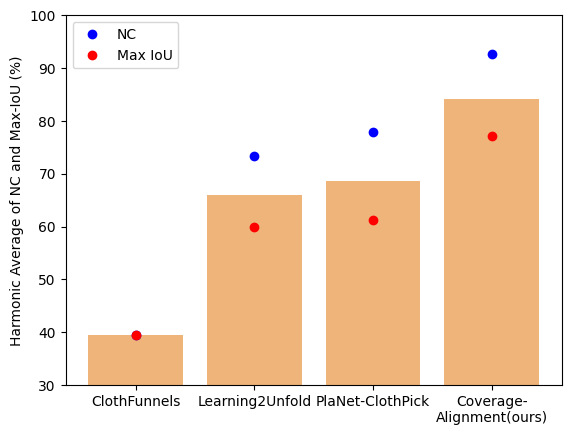

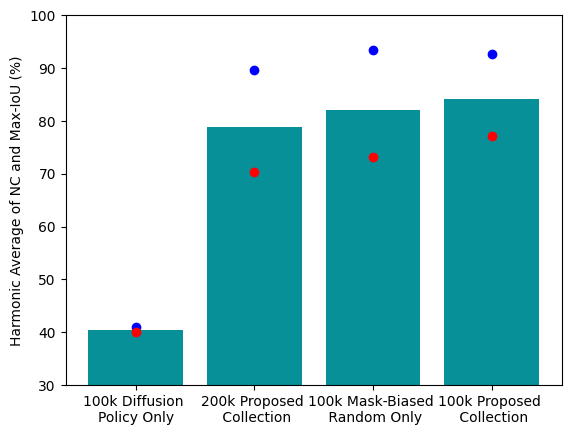

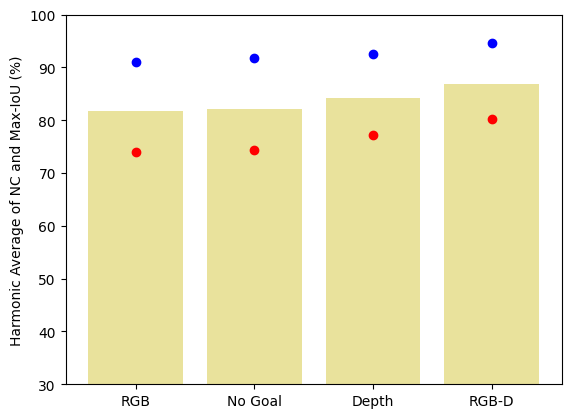

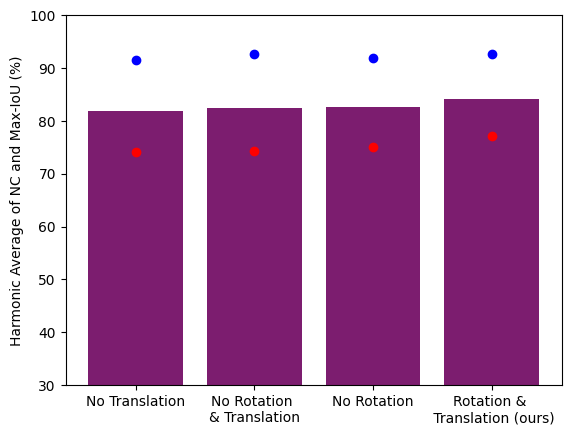

In [20]:
mono_df = df[(df['agent'] == 'planet-clothpick') & (df['config'].str.contains('abl'))]

config2ablation = {
    'D2M-on-mix-100k-sf-goal-rotate-translate-abl': 'No Goal Input',
    'GC-D2M-on-diffusion-100k-sf-goal-rotate-translate-abl': '100k Diffusion \nPolicy Only Data',
    'GC-D2M-on-mask-biased-100k-sf-goal-rotate-translate-abl': '100k Mask-Biased \n Random Only Data',
    'GC-D2M-on-mix-100k-cf-goal-rotate-translate-abl': 'ClothFunnels Reward',
    'GC-D2M-on-mix-100k-l2u-goal-rotate-translate-abl': 'Learning2Unfold Reward',
    'GC-D2M-on-mix-100k-pc-goal-rotate-translate-abl': 'PlaNet-ClothPick Reward',
    'GC-D2M-on-mix-100k-sf-goal-rotate-abl': 'No Translation Augmentation',
    'GC-D2M-on-mix-100k-sf-abl': 'No Rotation \n& Translation Augmentation',
    'GC-D2M-on-mix-100k-sf-goal-translate-abl': 'No Rotation Augmentation',
    'GC-D2M-on-mix-100k-sf-goal-rotate-translate-abl': "Default",
    'GC-D2M-on-mix-200k-sf-goal-rotate-translate-abl': "200k Proposed \n Collection Data",
    'GC-RGBD2M-on-mix-100k-sf-goal-rotate-translate-abl': 'RGB-D Input',
    'GC-RGB2M-on-mix-100k-sf-goal-rotate-translate-abl': 'RGB Input',
}

mono_df['config'] = mono_df['config'].apply(lambda x: config2ablation[x])
# display(mono_df)

## get the f1 score for each config using NC and IoU
mono_df['f1'] = 2*mono_df['nc']*mono_df['IoU']/(mono_df['nc'] + mono_df['IoU'])
mono_df['f1'] = mono_df['f1']*100
display(mono_df)

reward_df = mono_df[mono_df['config'].str.contains('Reward')]
# add the default config to make it as "Coverage-Alignment Reward"
reward_df = pd.concat([reward_df, mono_df[mono_df['config'] == 'Default']])
reward_df.loc[reward_df['config'] == 'Default', 'config'] = 'Coverage-\nAlignment(ours) Reward'
reward_df = reward_df.sort_values(by='f1')
## get rid of " Reward" in the config
reward_df['config'] = reward_df['config'].str.replace(' Reward', '')


y_min = 30
y_max = 100

## plot the f1 score for reward ablation, x-axis is the ablation, y-axis is the f1 score
plt.close()
plt.bar(reward_df['config'], reward_df['f1'], color='#EEB479')
# plt.xticks(rotation=45)
plt.plot(reward_df['config'], reward_df['nc']*100, color='blue', marker='o', linestyle='', label='NC')
plt.plot(reward_df['config'], reward_df['IoU']*100, color='red', marker='o', linestyle='', label='Max IoU')
plt.legend()
plt.ylabel('Harmonic Average of NC and Max-IoU (%)')
# plt.title('F1 Score for Reward Ablation')
plt.ylim(y_min, y_max)

plt.savefig(os.path.join(analysis_pth, 'fabric-f1-reward.png'), bbox_inches='tight')
plt.show()

## Plot the harminic mean of NC and IoU for data ablation
data_abl_df = mono_df[mono_df['config'].str.contains('Data')]
data_abl_df = pd.concat([data_abl_df, mono_df[mono_df['config'] == 'Default']])
data_abl_df.loc[data_abl_df['config'] == 'Default', 'config'] = '100k Proposed \n Collection Data'
data_abl_df = data_abl_df.sort_values(by='f1')
## get rid of " Data" in the config
data_abl_df['config'] = data_abl_df['config'].str.replace(' Data', '')

plt.close()
plt.bar(data_abl_df['config'], data_abl_df['f1'], color='#089099')
plt.plot(data_abl_df['config'], data_abl_df['nc']*100, color='blue', marker='o', linestyle='', label='NC')
plt.plot(data_abl_df['config'], data_abl_df['IoU']*100, color='red', marker='o', linestyle='', label='Max IoU')
# plt.xticks(rotation=45)
plt.ylabel('Harmonic Average of NC and Max-IoU (%)')
# plt.title('F1 Score for Reward Ablation')
plt.ylim(y_min, y_max)

plt.savefig(os.path.join(analysis_pth, 'fabric-f1-data.png'), bbox_inches='tight')
plt.show()

# Show variance of input data
input_df = mono_df[mono_df['config'].str.contains('Input')]
input_df = pd.concat([input_df, mono_df[mono_df['config'] == 'Default']])
input_df.loc[input_df['config'] == 'Default', 'config'] = 'Depth Input'
input_df = input_df.sort_values(by='f1')
## get rid of " Input" in the config
input_df['config'] = input_df['config'].str.replace(' Input', '')


plt.close()
plt.bar(input_df['config'], input_df['f1'], color='#E9E29C')
plt.plot(input_df['config'], input_df['nc']*100, color='blue', marker='o', linestyle='', label='NC')
plt.plot(input_df['config'], input_df['IoU']*100, color='red', marker='o', linestyle='', label='Max IoU')
# plt.xticks(rotation=45)
plt.ylabel('Harmonic Average of NC and Max-IoU (%)')
# plt.title('F1 Score for Reward Ablation')
plt.ylim(y_min, y_max)

plt.savefig(os.path.join(analysis_pth, 'fabric-f1-input.png'), bbox_inches='tight')
plt.show()

## show goal augmentation
goal_df = mono_df[mono_df['config'].str.contains('Augmentation')]
goal_df = pd.concat([goal_df, mono_df[mono_df['config'] == 'Default']])
goal_df.loc[goal_df['config'] == 'Default', 'config'] = 'Rotation & \n Translation (ours) Augmentation'
goal_df = goal_df.sort_values(by='f1')
## get rid of " Augmentation" in the config
goal_df['config'] = goal_df['config'].str.replace(' Augmentation', '')
plt.plot(goal_df['config'], goal_df['nc']*100, color='blue', marker='o', linestyle='', label='NC')
plt.plot(goal_df['config'], goal_df['IoU']*100, color='red', marker='o', linestyle='', label='Max IoU')

plt.close()
plt.bar(goal_df['config'], goal_df['f1'], color='#7C1D6F')
# plt.xticks(rotation=45)
plt.ylabel('Harmonic Average of NC and Max-IoU (%)')
plt.plot(goal_df['config'], goal_df['nc']*100, color='blue', marker='o', linestyle='', label='NC')
plt.plot(goal_df['config'], goal_df['IoU']*100, color='red', marker='o', linestyle='', label='Max IoU')
# plt.title('F1 Score for Reward Ablation')
plt.ylim(y_min, y_max)
# plt.title('F1 Score for Goal Augmentation')

plt.savefig(os.path.join(analysis_pth, 'fabric-f1-aug.png'), bbox_inches='tight')
plt.show()
